In [2]:
pip install pandas numpy matplotlib seaborn scipy statsmodels openpyxl scikit-learn

In [3]:
# ============================================================
# MODIS vs HLS VALIDATION
# FINAL INTEGRATED VERSION
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

# ============================================================
# SETTINGS
# ============================================================

WORKBOOK = "/content/drive/MyDrive/Colab Notebooks/HLS_MODIS_Lat_Long.xlsx"

PRE_YEARS = 3
POST_YEARS = 5

# ============================================================
# LOAD DATA
# ============================================================

print("Loading workbook...")

hls = pd.read_excel(
    WORKBOOK,
    sheet_name="HLS_monthly_NDVI (1) (1)"
)

lookup = pd.read_excel(
    WORKBOOK,
    sheet_name="Lat_Long"
)

modis = pd.read_excel(
    WORKBOOK,
    sheet_name="master_dataset_cleaned_1"
)

print("Workbook loaded.")

# ============================================================
# SITE IDS
# ============================================================

hls["site_clean"] = (
    hls["site_id"]
    .astype(str)
    .str.lower()
    .str.strip()
)

lookup["site_clean"] = (
    lookup["Plot_ID"]
    .astype(str)
    .str.lower()
    .str.strip()
)

modis["site_clean"] = (
    modis["plot_id"]
    .astype(str)
    .str.lower()
    .str.strip()
)

# ============================================================
# MORTALITY YEAR
# ============================================================

lookup["Mort_Year_observed"] = pd.to_numeric(
    lookup["Mort_Year_observed"],
    errors="coerce"
)

lookup_sub = (
    lookup[
        ["site_clean",
         "Mort_Year_observed"]
    ]
    .drop_duplicates()
)

# ============================================================
# MERGE MORTALITY YEAR
# ============================================================

hls = hls.merge(
    lookup_sub,
    on="site_clean",
    how="left"
)

modis = modis.merge(
    lookup_sub,
    on="site_clean",
    how="left"
)

siteyear = pd.merge(
    modis_siteyear,
    hls_siteyear,
    on=["site_clean", "year"],
    how="inner"
)

print("\nMatched site-year observations:")
print(len(siteyear))

# Remove NaNs

siteyear = siteyear.replace(
    [np.inf, -np.inf],
    np.nan
)

siteyear = siteyear.dropna(
    subset=[
        "modis_ndvi",
        "hls_ndvi"
    ]
)

print(
    "\nMatched site-year observations after cleaning:"
)

print(len(siteyear))

# ============================================================
# DATE VARIABLES
# ============================================================

hls["date"] = pd.to_datetime(
    hls["date"]
)

modis["date"] = pd.to_datetime(
    modis["date"]
)

hls["year"] = hls["date"].dt.year
modis["year"] = modis["date"].dt.year

# ============================================================
# NDVI VARIABLES
# ============================================================

HLS_VAR = "NDVI"
MODIS_VAR = "trend"

# ============================================================
# RELATIVE YEAR
# ============================================================

hls["rel_year"] = (
    hls["year"] -
    hls["Mort_Year_observed"]
)

modis["rel_year"] = (
    modis["year"] -
    modis["Mort_Year_observed"]
)

# ============================================================
# RELATIVE-YEAR TRAJECTORIES
# ============================================================

modis_rel = (
    modis
    .dropna(subset=["rel_year"])
    .groupby("rel_year")[MODIS_VAR]
    .agg(["mean","std","count"])
    .reset_index()
)

modis_rel["se"] = (
    modis_rel["std"] /
    np.sqrt(modis_rel["count"])
)

hls_rel = (
    hls
    .dropna(subset=["rel_year"])
    .groupby("rel_year")[HLS_VAR]
    .agg(["mean","std","count"])
    .reset_index()
)

hls_rel["se"] = (
    hls_rel["std"] /
    np.sqrt(hls_rel["count"])
)

# ============================================================
# RELATIVE-YEAR FIGURE
# ============================================================

fig, ax = plt.subplots(
    figsize=(12,8)
)

ax.plot(
    modis_rel["rel_year"],
    modis_rel["mean"],
    color="blue",
    lw=2,
    label="MODIS STL"
)

ax.fill_between(
    modis_rel["rel_year"],
    modis_rel["mean"] - modis_rel["se"],
    modis_rel["mean"] + modis_rel["se"],
    color="blue",
    alpha=0.25
)

ax.plot(
    hls_rel["rel_year"],
    hls_rel["mean"],
    color="green",
    lw=2,
    label="HLS SG"
)

ax.fill_between(
    hls_rel["rel_year"],
    hls_rel["mean"] - hls_rel["se"],
    hls_rel["mean"] + hls_rel["se"],
    color="green",
    alpha=0.25
)

ax.axvline(
    0,
    color="red",
    linestyle="--",
    lw=2
)

ax.set_xlabel(
    "Years relative to mortality"
)

ax.set_ylabel(
    "NDVI"
)

ax.set_title(
    "MODIS vs HLS Mortality Trajectories"
)

ax.legend()

plt.tight_layout()

plt.savefig(
    "Relative_Mortality_Trajectory.png",
    dpi=300
)

plt.show()

# ============================================================
# DECLINE CALCULATION
# ============================================================

def mortality_decline(
    d,
    value_col
):

    mort = d["Mort_Year_observed"].iloc[0]

    if pd.isna(mort):
        return None

    pre = d[
        (d["year"] >= mort-PRE_YEARS)
        &
        (d["year"] < mort)
    ]

    post = d[
        (d["year"] >= mort)
        &
        (d["year"] <= mort+POST_YEARS)
    ]

    if len(pre) == 0:
        return None

    if len(post) == 0:
        return None

    baseline = pre[value_col].quantile(0.95)

    minimum = post[value_col].min()

    absolute_decline = (
        baseline - minimum
    )

    percent_decline = (
        100 *
        absolute_decline /
        baseline
    )

    return pd.Series({

        "mort_year": mort,

        "baseline": baseline,

        "minimum": minimum,

        "decline_abs": absolute_decline,

        "decline_pct": percent_decline,

        "n_pre": len(pre),

        "n_post": len(post)

    })

# ============================================================
# SITE-LEVEL MODIS DECLINES
# ============================================================

modis_declines = (
    modis
    .groupby("site_clean")
    .apply(
        lambda x:
        mortality_decline(
            x,
            MODIS_VAR
        )
    )
    .dropna()
    .reset_index()
)

print(
    "\nMODIS decline sites:",
    len(modis_declines)
)

# ============================================================
# SITE-LEVEL HLS DECLINES
# ============================================================

hls_declines = (
    hls
    .groupby("site_clean")
    .apply(
        lambda x:
        mortality_decline(
            x,
            HLS_VAR
        )
    )
    .dropna()
    .reset_index()
)

print(
    "HLS decline sites:",
    len(hls_declines)
)

# ============================================================
# MATCH MORTALITY SITES
# ============================================================

matched = pd.merge(
    modis_declines,
    hls_declines,
    on="site_clean",
    suffixes=(
        "_modis",
        "_hls"
    )
)

print(
    "\nMatched mortality sites:",
    len(matched)
)

# ============================================================
# PERCENT DECLINE COMPARISON
# ============================================================

r_pct, _ = pearsonr(
    matched["decline_pct_modis"],
    matched["decline_pct_hls"]
)

rmse_pct = np.sqrt(
    mean_squared_error(
        matched["decline_pct_modis"],
        matched["decline_pct_hls"]
    )
)

print("\nPercent decline")
print("R =", round(r_pct,3))
print("RMSE =", round(rmse_pct,3))

plt.figure(figsize=(7,6))

sns.regplot(
    data=matched,
    x="decline_pct_modis",
    y="decline_pct_hls",
    ci=95
)

plt.xlabel(
    "MODIS decline (%)"
)

plt.ylabel(
    "HLS decline (%)"
)

plt.title(
    f"Percent decline comparison\nR={r_pct:.2f}"
)

plt.tight_layout()

plt.savefig(
    "Percent_Decline_Comparison.png",
    dpi=300
)

plt.show()

# ============================================================
# ABSOLUTE DECLINE COMPARISON
# ============================================================

r_abs, _ = pearsonr(
    matched["decline_abs_modis"],
    matched["decline_abs_hls"]
)

rmse_abs = np.sqrt(
    mean_squared_error(
        matched["decline_abs_modis"],
        matched["decline_abs_hls"]
    )
)

print("\nAbsolute decline")
print("R =", round(r_abs,3))
print("RMSE =", round(rmse_abs,3))

plt.figure(figsize=(7,6))

sns.regplot(
    data=matched,
    x="decline_abs_modis",
    y="decline_abs_hls",
    ci=95
)

plt.xlabel(
    "MODIS decline (NDVI)"
)

plt.ylabel(
    "HLS decline (NDVI)"
)

plt.title(
    f"Absolute decline comparison\nR={r_abs:.2f}"
)

plt.tight_layout()

plt.savefig(
    "Absolute_Decline_Comparison.png",
    dpi=300
)

plt.show()

# ============================================================
# SITE-YEAR VALIDATION
# ============================================================

print("\nCreating annual means...")

hls_siteyear = (
    hls
    .groupby(
        ["site_clean","year"]
    )[HLS_VAR]
    .mean()
    .reset_index()
)

hls_siteyear = hls_siteyear.rename(
    columns={
        HLS_VAR: "hls_ndvi"
    }
)

modis_siteyear = (
    modis
    .groupby(
        ["site_clean","year"]
    )[MODIS_VAR]
    .mean()
    .reset_index()
)

modis_siteyear = modis_siteyear.rename(
    columns={
        MODIS_VAR: "modis_ndvi"
    }
)

# ============================================================
# CREATE ANNUAL SITE-YEAR DATASETS
# ============================================================

modis_siteyear = (
    modis.groupby(["site_clean", "year"], as_index=False)
         .agg(
              modis_ndvi=("processed_ndvi", "mean")
         )
)

hls_siteyear = (
    hls.groupby(["site_clean", "year"], as_index=False)
       .agg(
            hls_ndvi=("processed_ndvi", "mean")
       )
)

print("MODIS site-years:", modis_siteyear.shape)
print("HLS site-years:", hls_siteyear.shape)

siteyear = pd.merge(
    modis_siteyear,
    hls_siteyear,
    on=[
        "site_clean",
        "year"
    ],
    how="inner"
)

print(
    "\nMatched site-year observations:",
    len(siteyear)
)

# ============================================================
## ============================================================
# FINAL SITEYEAR CLEANING
# ============================================================

siteyear["modis_ndvi"] = pd.to_numeric(
    siteyear["modis_ndvi"],
    errors="coerce"
)

siteyear["hls_ndvi"] = pd.to_numeric(
    siteyear["hls_ndvi"],
    errors="coerce"
)

siteyear = siteyear.replace(
    [np.inf, -np.inf],
    np.nan
)

siteyear = siteyear.dropna(
    subset=[
        "modis_ndvi",
        "hls_ndvi"
    ]
)

print(
    "\nCleaned site-year observations:",
    len(siteyear)
)

# ============================================================
# CREATE CLEAN ARRAYS
# ============================================================

x = siteyear["modis_ndvi"].to_numpy()

y = siteyear["hls_ndvi"].to_numpy()

print(
    "Remaining NaNs in MODIS:",
    np.isnan(x).sum()
)

print(
    "Remaining NaNs in HLS:",
    np.isnan(y).sum()
)

# ============================================================
# CALCULATE METRICS
# ============================================================

r_sy, p_sy = pearsonr(x, y)

rmse_sy = np.sqrt(
    np.mean(
        (x - y) ** 2
    )
)

mae_sy = np.mean(
    np.abs(x - y)
)

bias_sy = np.mean(
    y - x
)

print("\nSITE-YEAR VALIDATION")

print("n =", len(x))

print("R =", round(r_sy,3))

print("RMSE =", round(rmse_sy,3))

print("MAE =", round(mae_sy,3))

print("Bias =", round(bias_sy,3))

# ============================================================
# SITE-YEAR PLOT
# ============================================================

plt.figure(figsize=(8,6))

sns.regplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    ci=95
)

plt.xlabel(
    "MODIS annual mean NDVI"
)

plt.ylabel(
    "HLS annual mean NDVI"
)

plt.title(
    f"Site-Year Validation\nn={len(siteyear)}, R={r_sy:.2f}"
)

plt.tight_layout()

plt.savefig(
    "SiteYear_Validation.png",
    dpi=300
)

plt.show()

# ============================================================
# EXPORTS
# ============================================================

matched.to_csv(
    "Mortality_Site_Validation.csv",
    index=False
)

siteyear.to_csv(
    "SiteYear_Validation.csv",
    index=False
)

print("\nAnalysis complete.")
print("Mortality sites =", len(matched))
print("Site-year observations =", len(siteyear))

Loading workbook...
Workbook loaded.


NameError: name 'modis_siteyear' is not defined

In [4]:
print(modis.columns.tolist())
print(hls.columns.tolist())

['plot_id', 'date', 'ndvi', 'trend', 'residual', 'year', 'doy', 'country', 'event_date', 'climate', 'forest_type', 'quality', '%_mort', 'site_type', 'start_date', 'end_date', 'in_drought', 'lat', 'long', 'mort_year observed', 'site_clean', 'Mort_Year_observed']
['system:index', 'NDVI', 'date', 'month', 'site_id', 'year', '.geo', 'site_clean', 'Mort_Year_observed']


In [5]:
print("\nMatched site-year observations:")
print(len(siteyear))

print("\nUnique matched sites:")
print(siteyear["site_clean"].nunique())


Matched site-year observations:


NameError: name 'siteyear' is not defined

#diagnose why matched sites have dropped to only 12, insufficient for publication quality analysis

In [6]:
all_mod_sites = set(mod_declines["site_clean"])

all_hls_sites = set(hls_declines["site_clean"])

print("MODIS sites:", len(all_mod_sites))
print("HLS sites:", len(all_hls_sites))

print("Common sites:",
      len(all_mod_sites.intersection(all_hls_sites)))

NameError: name 'mod_declines' is not defined

Check which sites have positive versus negative change

In [7]:
compare.sort_values(
    "modis_decline"
)

NameError: name 'compare' is not defined

check mortality year distribution

In [8]:
print(
    modis.groupby(
        "Mort_Year_observed"
    )["site_clean"].nunique()
)

Mort_Year_observed
2004.0    2
2005.0    2
2006.0    1
2007.0    4
2008.0    5
2010.0    2
2011.0    2
2012.0    3
2013.0    7
2014.0    6
2016.0    8
2018.0    7
2019.0    2
2020.0    3
2021.0    1
2023.0    4
Name: site_clean, dtype: int64


We want to extend the analysis by classifying points in the scatter plot by forest type - first merge column into site year dataframe then plot the figure

In [9]:
forest_lookup = (
    modis[
        ["site_clean", "forest_type"]
    ]
    .drop_duplicates()
)

siteyear = siteyear.merge(
    forest_lookup,
    on="site_clean",
    how="left"
)

NameError: name 'siteyear' is not defined

Merge duplicate forest types

In [ ]:
siteyear["forest_type"] = (
    siteyear["forest_type"]
    .astype(str)
    .str.strip()
    .str.title()
)

Check

In [ ]:
siteyear["forest_type"] = (
    siteyear["forest_type"]
    .astype(str)
    .str.strip()
    .str.title()
)

In [ ]:
plt.figure(figsize=(9,7))

sns.scatterplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    hue="forest_type",
    alpha=0.7
)

sns.regplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    scatter=False,
    color="black"
)

plt.xlabel("MODIS annual mean NDVI")
plt.ylabel("HLS annual mean NDVI")

plt.title(
    "Site-Year Validation by Forest Type"
)

plt.tight_layout()
plt.show()

add R values by forest type

In [ ]:
for forest, g in siteyear.groupby("forest_type"):

    if len(g) > 10:

        r = g["modis_ndvi"].corr(
            g["hls_ndvi"]
        )

        print(
            f"{forest}: "
            f"n={len(g)}, "
            f"R={r:.3f}"
        )

Create publication quality figure

In [ ]:
from scipy.stats import pearsonr

forests = sorted(
    siteyear["forest_type"]
    .dropna()
    .unique()
)

fig, axes = plt.subplots(
    1,
    len(forests),
    figsize=(5*len(forests),5),
    sharex=True,
    sharey=True
)

for ax, forest in zip(axes, forests):

    d = siteyear[
        siteyear["forest_type"] == forest
    ]

    sns.regplot(
        data=d,
        x="modis_ndvi",
        y="hls_ndvi",
        ax=ax,
        scatter_kws={
            "alpha":0.6,
            "s":30
        }
    )

    r, _ = pearsonr(
        d["modis_ndvi"],
        d["hls_ndvi"]
    )

    ax.set_title(
        f"{forest}\nR={r:.2f}\nn={len(d)}"
    )

plt.tight_layout()
plt.show()

fixed palette by forest type

In [ ]:
forest_palette = {
    "Conifer": "#1f77b4",      # blue
    "Deciduous": "#2ca02c",    # green
    "Mixed": "#ff7f0e"         # orange
}

make sure classes are cleaned

In [ ]:
siteyear["forest_type"] = (
    siteyear["forest_type"]
    .astype(str)
    .str.strip()
    .str.title()
)

print(siteyear["forest_type"].value_counts())

Draw forest type scatter plot

In [ ]:
plt.figure(figsize=(9,7))

sns.scatterplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    hue="forest_type",
    palette=forest_palette,
    alpha=0.75,
    s=50
)

sns.regplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    scatter=False,
    color="black"
)

plt.title(
    f"Site-Year Validation by Forest Type\n"
    f"Overall R = {r_sy:.2f}, n = {len(siteyear)}"
)

plt.xlabel("MODIS annual mean NDVI")
plt.ylabel("HLS annual mean NDVI")

plt.tight_layout()
plt.show()

Compute forest type-specific R values

In [ ]:
for forest, g in siteyear.groupby("forest_type"):

    if len(g) > 10:

        r = g["modis_ndvi"].corr(
            g["hls_ndvi"]
        )

        print(
            f"{forest}: n={len(g)}, R={r:.3f}"
        )

Redraw faceted plot (separate plot for each separate forest type) with relevant colour categories

In [ ]:
from scipy.stats import pearsonr

forests = sorted(
    siteyear["forest_type"]
    .dropna()
    .unique()
)

fig, axes = plt.subplots(
    1,
    len(forests),
    figsize=(5*len(forests),5),
    sharex=True,
    sharey=True
)

for ax, forest in zip(axes, forests):

    d = siteyear[
        siteyear["forest_type"] == forest
    ]

    sns.regplot(
        data=d,
        x="modis_ndvi",
        y="hls_ndvi",
        ax=ax,
        color=forest_palette[forest],
        scatter_kws={
            "alpha":0.6,
            "s":35
        }
    )
    #add 1:1 line
    xmin = min(
    d["modis_ndvi"].min(),
    d["hls_ndvi"].min()
    )

    xmax = max(
    d["modis_ndvi"].max(),
    d["hls_ndvi"].max()
    )

    ax.plot(
    [xmin, xmax],
    [xmin, xmax],
    "k--",
    lw=1
    )

    r, _ = pearsonr(
        d["modis_ndvi"],
        d["hls_ndvi"]
    )

    ax.set_title(
        f"{forest}\nR={r:.2f}\nn={len(d)}"
    )

plt.tight_layout()
plt.show()

And classified by mortality severity -add mortality back into the lookup table, create severity categories and plot

Add mortality severity back into the site year. FIrst create a lookup table

In [ ]:
mort_lookup = (
    modis[
        ["site_clean", "%_mort"]
    ]
    .drop_duplicates()
)


Then merge

In [ ]:
siteyear = siteyear.merge(
    mort_lookup,
    on="site_clean",
    how="left"
)

Check

In [ ]:
print(siteyear.columns)

we have too many %_mort columns - check they are identical then keep just one

In [ ]:
print(
    (siteyear["%_mort_x"] == siteyear["%_mort_y"])
    .value_counts(dropna=False)
)

Nearly all True so keep %_mort_x and delete %_mort_y

In [ ]:
siteyear["mortality_pct"] = siteyear["%_mort_x"]

siteyear = siteyear.drop(
    columns=["%_mort_x", "%_mort_y"]
)

Then create severity classes

In [ ]:
siteyear["mort_class"] = pd.cut(
    siteyear["mortality_pct"],
    bins=[0,25,50,75,100],
    labels=[
        "Low",
        "Moderate",
        "High",
        "Severe"
    ]
)

Check sample sizes

In [ ]:
print(
    siteyear["mort_class"]
    .value_counts(dropna=False)
)

then create mortality severity scatter plot

In [ ]:
severity_palette = {
    "Low": "#1f77b4",        # blue
    "Moderate": "#ff7f0e",   # orange
    "High": "#d62728",       # red
    "Severe": "#800080"      # purple
}

plt.figure(figsize=(9,7))

sns.scatterplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    hue="mort_class",
    palette=severity_palette,
    alpha=0.8,
    s=50
)

sns.regplot(
    data=siteyear,
    x="modis_ndvi",
    y="hls_ndvi",
    scatter=False,
    color="black"
)

plt.xlabel("MODIS annual mean NDVI")
plt.ylabel("HLS annual mean NDVI")

plt.title(
    f"Site-Year Validation by Mortality Severity\n"
    f"Overall R = {r_sy:.2f}, n = {len(siteyear)}"
)

plt.tight_layout()
plt.show()

Mortality severity facet plot

In [ ]:
from scipy.stats import pearsonr

severity_order = [
    "Low",
    "Moderate",
    "High",
    "Severe"
]

severity_palette = {
    "Low": "#1f77b4",        # blue
    "Moderate": "#ff7f0e",   # orange
    "High": "#d62728",       # red
    "Severe": "#800080"      # purple
}

fig, axes = plt.subplots(
    1,
    len(severity_order),
    figsize=(20,5),
    sharex=True,
    sharey=True
)

for ax, severity in zip(axes, severity_order):

    d = siteyear[
        siteyear["mort_class"] == severity
    ].copy()

    if len(d) < 5:
        ax.set_visible(False)
        continue

    sns.regplot(
        data=d,
        x="modis_ndvi",
        y="hls_ndvi",
        ax=ax,
        color=severity_palette[severity],
        scatter_kws={
            "alpha":0.65,
            "s":35
        }
    )

#add 1:1 line
    xmin = min(
    d["modis_ndvi"].min(),
    d["hls_ndvi"].min()
    )

    xmax = max(
    d["modis_ndvi"].max(),
    d["hls_ndvi"].max()
    )

    ax.plot(
    [xmin, xmax],
    [xmin, xmax],
    "k--",
    lw=1
    )

    r, p = pearsonr(
        d["modis_ndvi"],
        d["hls_ndvi"]
    )

    ax.set_title(
        f"{severity}\n"
        f"R = {r:.2f}\n"
        f"n = {len(d)}"
    )

    ax.set_xlabel("MODIS NDVI")

axes[0].set_ylabel("HLS NDVI")

#plt.suptitle(
 #   "MODIS-HLS Agreement by Mortality Severity",
  #  fontsize=14,
   # y=1.03
#)

plt.tight_layout()

plt.savefig(
    "MortalitySeverity_Facets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

We need to carry out the same STL data processing on MODIS and HLS data  

In [ ]:
import pandas as pd

file = "/content/drive/MyDrive/Colab Notebooks/HLS_MODIS_Lat_Long.xlsx"

xls = pd.ExcelFile(file)

print("Sheets:")
print(xls.sheet_names)

for sheet in xls.sheet_names:
    df = pd.read_excel(file, sheet_name=sheet)
    print("\n---", sheet, "---")
    print(df.columns.tolist())

In [ ]:
import pandas as pd
import numpy as np

from scipy.signal import savgol_filter
from statsmodels.tsa.seasonal import STL

# =====================================================
# LOAD DATA
# =====================================================

file = "/content/drive/MyDrive/Colab Notebooks/HLS_MODIS_Lat_Long.xlsx"

hls = pd.read_excel(
    file,
    sheet_name="HLS_monthly_NDVI (1) (1)"
)

lookup = pd.read_excel(
    file,
    sheet_name="Lat_Long"
)

# =====================================================
# DATE FORMAT
# =====================================================

hls["date"] = pd.to_datetime(hls["date"])

# =====================================================
# PROCESS EACH SITE
# =====================================================

results = []

for site, d in hls.groupby("site_id"):

    d = d.sort_values("date").copy()

    if len(d) < 24:
        continue

    # -----------------------------------------
    # Create full monthly sequence
    # -----------------------------------------

    full_dates = pd.date_range(
        start=d["date"].min(),
        end=d["date"].max(),
        freq="MS"
    )

    d = (
        d.set_index("date")
         .reindex(full_dates)
         .rename_axis("date")
         .reset_index()
    )

    d["site_id"] = site

    d["NDVI"] = d["NDVI"].interpolate(
        limit_direction="both"
    )

    # -----------------------------------------
    # Savitzky-Golay smoothing
    # -----------------------------------------

    n = len(d)

    window = min(11, n)

    if window % 2 == 0:
        window -= 1

    if window < 5:
        continue

    d["sg_ndvi"] = savgol_filter(
        d["NDVI"],
        window_length=window,
        polyorder=2
    )

    # -----------------------------------------
    # STL decomposition
    # -----------------------------------------

    stl = STL(
        d["sg_ndvi"],
        period=12,
        robust=True
    )

    fit = stl.fit()

    d["trend"] = fit.trend
    d["seasonal"] = fit.seasonal
    d["residual"] = fit.resid

    # -----------------------------------------
    # Recompose
    # -----------------------------------------

    d["processed_ndvi"] = (
        d["trend"] +
        d["seasonal"]
    )

    results.append(d)

# =====================================================
# COMBINE SITES
# =====================================================

hls_processed = pd.concat(
    results,
    ignore_index=True
)

# =====================================================
# ANNUAL MEANS
# =====================================================

hls_processed["year"] = (
    hls_processed["date"].dt.year
)

annual_hls = (
    hls_processed
    .groupby(
        ["site_id", "year"]
    )["processed_ndvi"]
    .mean()
    .reset_index()
)

annual_hls.rename(
    columns={
        "processed_ndvi": "hls_ndvi"
    },
    inplace=True
)

# =====================================================
# ADD MORTALITY YEAR
# =====================================================

lookup["Plot_ID"] = lookup["Plot_ID"].astype(str)
annual_hls["site_id"] = annual_hls["site_id"].astype(str)

annual_hls = annual_hls.merge(
    lookup[
        ["Plot_ID",
         "Mort_Year_observed"]
    ],
    left_on="site_id",
    right_on="Plot_ID",
    how="left"
)

# =====================================================
# SAVE OUTPUTS
# =====================================================

hls_processed.to_csv(
    "HLS_SG_STL")

In [ ]:
print(
    annual_hls["Mort_Year_observed"]
    .notna()
    .sum()
)

print(
    annual_hls["site_id"]
    .nunique()
)

print(
    annual_hls["Mort_Year_observed"]
    .dropna()
    .nunique()
)

How many sites received a mortality year assignment

In [ ]:
annual_hls.loc[
    annual_hls["Mort_Year_observed"].notna(),
    "site_id"
].nunique()


In [ ]:
annual_hls["Mort_Year_observed"].isna().mean()

Check the STL has had an effectby comparing with SG only values

In [ ]:
annual_sg = (
    hls_processed
    .groupby(["site_id","year"])["sg_ndvi"]
    .mean()
    .reset_index(name="sg_ndvi")
)

compare = annual_hls.merge(
    annual_sg,
    on=["site_id","year"]
)

print(
    compare[["hls_ndvi","sg_ndvi"]]
    .corr()
)

rerun analysis with STL data

In [ ]:
# =====================================================
# PREPARE TRAJECTORY DATA
# =====================================================

traj = annual_hls.copy()

traj = traj[
    traj["Mort_Year_observed"].notna()
].copy()

traj["Mort_Year_observed"] = (
    traj["Mort_Year_observed"]
    .astype(int)
)

traj["relative_year"] = (
    traj["year"] -
    traj["Mort_Year_observed"]
)

# keep +/- 3 year window
traj = traj[
    traj["relative_year"].between(-3, 3)
]

calculate mean trajectory

In [ ]:
trajectory = (
    traj.groupby("relative_year")["hls_ndvi"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

trajectory["se"] = (
    trajectory["std"] /
    np.sqrt(trajectory["count"])
)

print(trajectory)

plot

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.plot(
    trajectory["relative_year"],
    trajectory["mean"],
    marker="o",
    linewidth=2
)

plt.fill_between(
    trajectory["relative_year"],
    trajectory["mean"] - trajectory["se"],
    trajectory["mean"] + trajectory["se"],
    alpha=0.2
)

plt.axvline(
    0,
    color="red",
    linestyle="--",
    label="Mortality year"
)

plt.xlabel("Years relative to mortality")
plt.ylabel("HLS NDVI (SG + STL)")
plt.title("Mean HLS mortality trajectory")
plt.legend()

plt.show()

for site normalised trajectories

In [ ]:
traj["site_baseline"] = (
    traj.groupby("site_id")["hls_ndvi"]
    .transform("mean")
)

traj["norm_ndvi"] = (
    traj["hls_ndvi"] -
    traj["site_baseline"]
)


In [ ]:
trajectory_norm = (
    traj.groupby("relative_year")["norm_ndvi"]
    .agg(["mean","std","count"])
    .reset_index()
)

trajectory_norm["se"] = (
    trajectory_norm["std"] /
    np.sqrt(trajectory_norm["count"])
)

plot

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    trajectory_norm["relative_year"],
    trajectory_norm["mean"],
    marker="o",
    linewidth=2
)

plt.fill_between(
    trajectory_norm["relative_year"],
    trajectory_norm["mean"] - trajectory_norm["se"],
    trajectory_norm["mean"] + trajectory_norm["se"],
    alpha=0.2
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Years relative to mortality")
plt.ylabel("Normalised HLS NDVI")
plt.title("Normalised HLS mortality trajectory (SG + STL)")

plt.show()

Print sample sizes

In [ ]:
print(
    traj.groupby("relative_year")
    .site_id.nunique()
)

run site normalised HLS mortality trajectory

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

traj = annual_hls.copy()

traj = traj[
    traj["Mort_Year_observed"].notna()
].copy()

traj["relative_year"] = (
    traj["year"]
    - traj["Mort_Year_observed"]
)

traj = traj[
    traj["relative_year"].between(-3, 3)
]

# site mean-centering

traj["site_mean"] = (
    traj.groupby("site_id")["hls_ndvi"]
    .transform("mean")
)

traj["norm_ndvi"] = (
    traj["hls_ndvi"]
    - traj["site_mean"]
)

summary = (
    traj.groupby("relative_year")["norm_ndvi"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

summary["se"] = (
    summary["std"]
    / np.sqrt(summary["count"])
)

plt.figure(figsize=(8,5))

plt.plot(
    summary["relative_year"],
    summary["mean"],
    marker="o",
    linewidth=2
)

plt.fill_between(
    summary["relative_year"],
    summary["mean"] - summary["se"],
    summary["mean"] + summary["se"],
    alpha=0.2
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel("Years relative to mortality")
plt.ylabel("Normalised HLS NDVI")
plt.title("HLS mortality trajectory (SG-STL processed)")

plt.tight_layout()
plt.show()

forest type mortality trajs

In [ ]:
modis = pd.read_excel(
    file,
    sheet_name="master_dataset_cleaned_1"
)

forest_lookup = (
    modis[
        ["plot_id", "forest_type"]
    ]
    .drop_duplicates()
)

forest_lookup["plot_id"] = (
    forest_lookup["plot_id"]
    .astype(str)
)

traj["site_id"] = (
    traj["site_id"].astype(str)
)

traj = traj.merge(
    forest_lookup,
    left_on="site_id",
    right_on="plot_id",
    how="left"
)

In [ ]:
import seaborn as sns

g = sns.FacetGrid(
    traj,
    col="forest_type",
    col_wrap=3,
    height=4,
    sharey=True
)

g.map_dataframe(
    sns.lineplot,
    x="relative_year",
    y="norm_ndvi",
    errorbar=("se", 1)
)

for ax in g.axes.flat:
    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

g.set_axis_labels(
    "Years relative to mortality",
    "Normalised NDVI"
)

plt.show()

mortalty severity vs NDVI decline

In [ ]:
declines = []

for site, d in annual_hls.groupby("site_id"):

    d = d.dropna(
        subset=["Mort_Year_observed"]
    )

    if len(d) == 0:
        continue

    mort_year = int(
        d["Mort_Year_observed"].iloc[0]
    )

    pre = d[
        d["year"].between(
            mort_year - 1,
            mort_year
        )
    ]["hls_ndvi"].mean()

    post = d[
        d["year"].between(
            mort_year + 1,
            mort_year + 3
        )
    ]["hls_ndvi"].mean()

    if pd.isna(pre) or pd.isna(post):
        continue

    decline = (
        100 * (pre - post) / pre
    )

    declines.append(
        [site, decline]
    )

declines = pd.DataFrame(
    declines,
    columns=[
        "site_id",
        "hls_decline_pct"
    ]
)

add mort severity

In [ ]:
mortality = (
    modis[
        ["plot_id", "%_mort"]
    ]
    .drop_duplicates()
)

mortality["plot_id"] = (
    mortality["plot_id"]
    .astype(str)
)

declines["site_id"] = (
    declines["site_id"]
    .astype(str)
)

declines = declines.merge(
    mortality,
    left_on="site_id",
    right_on="plot_id",
    how="left"
)

plot and test correlation

In [ ]:
from scipy.stats import spearmanr

rho, p = spearmanr(
    declines["%_mort"],
    declines["hls_decline_pct"],
    nan_policy="omit"
)

print("Spearman rho =", rho)
print("p =", p)

plt.figure(figsize=(7,5))

sns.regplot(
    data=declines,
    x="%_mort",
    y="hls_decline_pct"
)

plt.xlabel("Mortality severity (%)")
plt.ylabel("HLS decline (%)")

plt.title(
    f"rho={rho:.2f}, p={p:.3f}"
)

plt.show()

MODIS HLS comparison - annual agreement between sensors

In [ ]:
modis["mort_year observed"] = pd.to_numeric(
    modis["mort_year observed"],
    errors="coerce"
)

modis_annual = (
    modis.groupby(
        ["plot_id", "year"]
    )["trend"]
    .mean()
    .reset_index(name="modis_ndvi")
)

modis_annual["plot_id"] = (
    modis_annual["plot_id"]
    .astype(str)
)

annual_hls["site_id"] = (
    annual_hls["site_id"]
    .astype(str)
)

comparison = annual_hls.merge(
    modis_annual,
    left_on=["site_id", "year"],
    right_on=["plot_id", "year"],
    how="inner"
)

print(
    comparison[
        ["hls_ndvi", "modis_ndvi"]
    ].corr()
)

In [ ]:
plt.figure(figsize=(6,6))

sns.regplot(
    data=comparison,
    x="modis_ndvi",
    y="hls_ndvi"
)

plt.xlabel("MODIS NDVI")
plt.ylabel("HLS NDVI")

plt.title(
    f"n={len(comparison)}"
)

plt.show()

Compute site metrics

In [ ]:
import pandas as pd
import numpy as np

site_metrics = []

for site, d in annual_hls.groupby("site_id"):

    d = d.copy()

    if d["Mort_Year_observed"].isna().all():
        continue

    mort_year = int(
        d["Mort_Year_observed"].dropna().iloc[0]
    )

    pre = d[
        d["year"].between(
            mort_year-1,
            mort_year
        )
    ]["hls_ndvi"].mean()

    post = d[
        d["year"].between(
            mort_year+1,
            mort_year+3
        )
    ]["hls_ndvi"].mean()

    if pd.isna(pre) or pd.isna(post):
        continue

    decline_abs = pre - post

    decline_pct = (
        100 * (pre - post) / pre
    )

    site_metrics.append([
        site,
        mort_year,
        pre,
        post,
        decline_abs,
        decline_pct
    ])

site_metrics = pd.DataFrame(
    site_metrics,
    columns=[
        "site_id",
        "mort_year",
        "pre_ndvi",
        "post_ndvi",
        "abs_decline",
        "pct_decline"
    ]
)

print(site_metrics.head())

site_metrics.to_csv(
    "site_level_metrics.csv",
    index=False
)

rank sites by declines

In [ ]:
site_metrics.sort_values(
    "pct_decline",
    ascending=False
).head(20)

individual site trajectory plots

In [ ]:
import os
import matplotlib.pyplot as plt

os.makedirs(
    "site_figures",
    exist_ok=True
)

for site, d in annual_hls.groupby("site_id"):

    d = d.copy()

    if d["Mort_Year_observed"].isna().all():
        continue

    mort_year = int(
        d["Mort_Year_observed"].dropna().iloc[0]
    )

    plt.figure(figsize=(6,4))

    plt.plot(
        d["year"],
        d["hls_ndvi"],
        marker="o"
    )

    plt.axvline(
        mort_year,
        color="red",
        linestyle="--"
    )

    plt.title(f"Site {site}")
    plt.ylabel("HLS NDVI")
    plt.xlabel("Year")

    plt.tight_layout()

    plt.savefig(
        f"site_figures/{site}.png",
        dpi=200
    )

    plt.close()

relative year site plots - useful for comparison

In [ ]:
for site, d in annual_hls.groupby("site_id"):

    if d["Mort_Year_observed"].isna().all():
        continue

    mort = int(
        d["Mort_Year_observed"].dropna().iloc[0]
    )

    d = d.copy()

    d["relative_year"] = (
        d["year"] - mort
    )

    d = d[
        d["relative_year"].between(-5,5)
    ]

    plt.figure(figsize=(5,4))

    plt.plot(
        d["relative_year"],
        d["hls_ndvi"],
        marker="o"
    )

    plt.axvline(
        0,
        color="red",
        linestyle="--"
    )

    plt.xlabel(
        "Years relative to mortality"
    )

    plt.ylabel(
        "HLS NDVI"
    )

    plt.title(
        f"{site}"
    )

    plt.show()

Create matched MODIS-HLS annual dataset - first aggregate MODIS to annual means

In [ ]:
modis_annual = (
    modis
    .groupby(["plot_id", "year"])
    .agg(
        modis_ndvi=("trend", "mean"),
        forest_type=("forest_type", "first"),
        mort_pct=("%_mort", "first"),
        mort_year=("mort_year observed", "first")
    )
    .reset_index()
)

modis_annual["plot_id"] = (
    modis_annual["plot_id"]
    .astype(str)
)

annual_hls["site_id"] = (
    annual_hls["site_id"]
    .astype(str)
)

create site_clean

In [ ]:
traj["site_clean"] = (
    traj["site_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

create in modis too

In [ ]:
modis["site_clean"] = (
    modis["plot_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

rebuild lookup

In [ ]:
forest_lookup = (
    modis[
        ["site_clean", "forest_type"]
    ]
    .drop_duplicates()
)

now merge

In [ ]:
traj = traj.merge(
    forest_lookup,
    on="site_clean",
    how="left"
)

In [ ]:
print("Direct matches:", len(matches))
print(sorted(matches)[:50])

rebuild matched dataset

In [ ]:
# Standardise IDs

annual_hls["site_clean"] = (
    annual_hls["site_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

modis["site_clean"] = (
    modis["plot_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# retain only matched sites

matched_sites = set(
    annual_hls["site_clean"]
).intersection(
    set(modis["site_clean"])
)

print("Matched sites:", len(matched_sites))

Create standardised lookup

In [ ]:
annual_hls["site_clean"] = (
    annual_hls["site_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

modis["site_clean"] = (
    modis["plot_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

clean forest type labels

In [ ]:
modis["forest_type"] = (
    modis["forest_type"]
    .str.strip()
    .str.lower()
)

modis["forest_type"] = (
    modis["forest_type"]
    .replace({
        "conifer":"Conifer",
        "deciduous":"Deciduous",
        "mixed":"Mixed"
    })
)

create forest loookup

In [ ]:
forest_lookup = (
    modis[
        ["site_clean","forest_type"]
    ]
    .drop_duplicates()
)

build trajectory dataset

In [ ]:
traj = annual_hls.copy()

traj = traj[
    traj["site_clean"].isin(
        matched_sites
    )
]

traj = traj.merge(
    forest_lookup,
    on="site_clean",
    how="left"
)

In [ ]:
print(
    traj["forest_type"]
    .value_counts(dropna=False)
)

forest type trajectory figure

In [ ]:
traj = traj[
    traj["Mort_Year_observed"].notna()
].copy()

traj["relative_year"] = (
    traj["year"]
    - traj["Mort_Year_observed"]
)

traj = traj[
    traj["relative_year"].between(-3,3)
]

traj["site_mean"] = (
    traj.groupby("site_clean")["hls_ndvi"]
    .transform("mean")
)

traj["norm_ndvi"] = (
    traj["hls_ndvi"]
    - traj["site_mean"]
)

summary

In [ ]:
summary = (
    traj
    .groupby(
        ["forest_type","relative_year"]
    )["norm_ndvi"]
    .agg(["mean","std","count"])
    .reset_index()
)

summary["se"] = (
    summary["std"]
    / np.sqrt(summary["count"])
)

print(
    summary.groupby("forest_type")
    ["count"]
    .max()
)

facet plot

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

g = sns.FacetGrid(
    summary,
    col="forest_type",
    col_wrap=3,
    height=4,
    sharey=True
)

g.map_dataframe(
    sns.lineplot,
    x="relative_year",
    y="mean",
    marker="o"
)

for ax in g.axes.flat:
    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

g.set_axis_labels(
    "Years relative to mortality",
    "Normalised NDVI"
)

plt.show()


comparison plot

In [ ]:
plt.figure(figsize=(9,6))

sns.lineplot(
    data=summary,
    x="relative_year",
    y="mean",
    hue="forest_type",
    marker="o",
    linewidth=2
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel(
    "Years relative to mortality"
)

plt.ylabel(
    "Normalised NDVI"
)

plt.title(
    "Mortality trajectories by forest type"
)

plt.tight_layout()
plt.show()

In [ ]:
summary[
    ["forest_type",
     "relative_year",
     "count"]
]

In [ ]:
traj["forest_type"] = (
    traj["forest_type"]
    .str.strip()
    .str.lower()
)

In [ ]:
traj["forest_type"] = (
    traj["forest_type"]
    .replace({
        "mixed": "Mixed",
        "conifer": "Conifer",
        "deciduous": "Deciduous"
    })
)

In [ ]:
print(
    traj["forest_type"]
    .value_counts()
)

merge

In [ ]:
traj = traj.merge(
    forest_lookup,
    on="site_clean",
    how="left"
)


merge with HLS

In [ ]:
matched = annual_hls.merge(
    modis_annual,
    left_on=["site_id", "year"],
    right_on=["plot_id", "year"],
    how="inner"
)

print("Matched rows:", len(matched))
print("Matched sites:", matched["site_id"].nunique())

calculate site metrics for both sensors

In [ ]:
site_metrics = []

for site, d in matched.groupby("site_id"):

    d = d.sort_values("year")

    mort_year = d["mort_year"].dropna()

    if len(mort_year) == 0:
        continue

    mort_year = int(mort_year.iloc[0])

    # HLS

    hls_pre = d[
        d["year"].between(
            mort_year-1,
            mort_year
        )
    ]["hls_ndvi"].mean()

    hls_post = d[
        d["year"].between(
            mort_year+1,
            mort_year+3
        )
    ]["hls_ndvi"].mean()

    # MODIS

    modis_pre = d[
        d["year"].between(
            mort_year-1,
            mort_year
        )
    ]["modis_ndvi"].mean()

    modis_post = d[
        d["year"].between(
            mort_year+1,
            mort_year+3
        )
    ]["modis_ndvi"].mean()

    if (
        pd.isna(hls_pre) or
        pd.isna(hls_post) or
        pd.isna(modis_pre) or
        pd.isna(modis_post)
    ):
        continue

    hls_decline_pct = (
        100 * (hls_pre - hls_post) / hls_pre
    )

    modis_decline_pct = (
        100 * (modis_pre - modis_post) / modis_pre
    )

    corr = (
        d[["hls_ndvi","modis_ndvi"]]
        .corr()
        .iloc[0,1]
    )

    site_metrics.append([

        site,

        mort_year,

        d["forest_type"].iloc[0],

        d["mort_pct"].iloc[0],

        hls_decline_pct,

        modis_decline_pct,

        corr

    ])

site_metrics = pd.DataFrame(

    site_metrics,

    columns=[

        "site_id",
        "mort_year",
        "forest_type",
        "mortality_pct",

        "hls_decline_pct",
        "modis_decline_pct",

        "sensor_corr"
    ]
)

site_metrics.head()

save

In [ ]:
site_metrics.to_csv(
    "site_metrics_HLS_MODIS.csv",
    index=False
)

site specific comparison charts

In [ ]:
import matplotlib.pyplot as plt
import os

os.makedirs(
    "matched_site_figures",
    exist_ok=True
)

for site, d in matched.groupby("site_id"):

    d = d.sort_values("year")

    mort = d["mort_year"].dropna()

    if len(mort) == 0:
        continue

    mort = int(mort.iloc[0])

    plt.figure(figsize=(8,5))

    plt.plot(
        d["year"],
        d["hls_ndvi"],
        marker="o",
        linewidth=2,
        label="HLS"
    )

    plt.plot(
        d["year"],
        d["modis_ndvi"],
        marker="s",
        linewidth=2,
        label="MODIS"
    )

    plt.axvline(
        mort,
        color="red",
        linestyle="--",
        label="Mortality year"
    )

    plt.title(f"Site {site}")

    plt.xlabel("Year")

    plt.ylabel("NDVI")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"matched_site_figures/{site}.png",
        dpi=300
    )

    plt.close()

FOrest type mortality trajectories

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------
# Normalise within site
# ---------------------------------

traj["site_mean"] = (
    traj.groupby("site_id")["hls_ndvi"]
    .transform("mean")
)

traj["norm_ndvi"] = (
    traj["hls_ndvi"]
    - traj["site_mean"]
)

# ---------------------------------
# Summary statistics
# ---------------------------------

summary = (
    traj
    .groupby(
        ["forest_type", "relative_year"]
    )["norm_ndvi"]
    .agg(["mean","std","count"])
    .reset_index()
)

summary["se"] = (
    summary["std"]
    / np.sqrt(summary["count"])
)

# ---------------------------------
# Plot
# ---------------------------------

forest_types = (
    summary["forest_type"]
    .dropna()
    .unique()
)

n = len(forest_types)

fig, axes = plt.subplots(
    int(np.ceil(n/3)),
    3,
    figsize=(15,4*np.ceil(n/3)),
    sharey=True
)

axes = axes.flatten()

for ax, ft in zip(axes, forest_types):

    d = summary[
        summary["forest_type"]==ft
    ]

    ax.plot(
        d["relative_year"],
        d["mean"],
        marker="o",
        linewidth=2
    )

    ax.fill_between(
        d["relative_year"],
        d["mean"]-d["se"],
        d["mean"]+d["se"],
        alpha=0.25
    )

    ax.axvline(
        0,
        color="red",
        linestyle="--"
    )

    ax.set_title(ft)

    ax.set_xlabel(
        "Years relative to mortality"
    )

    ax.set_ylabel(
        "Normalised NDVI"
    )

plt.tight_layout()
plt.show()

In [ ]:
print(modis["forest_type"].value_counts())

print(traj["forest_type"].value_counts(dropna=False))

print(traj["site_id"].astype(str).unique()[:10])

print(modis["plot_id"].astype(str).unique()[:10])

In [ ]:
diagnose matching success

In [ ]:
hls_sites = set(
    annual_hls["site_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

modis_sites = set(
    modis["plot_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("HLS sites:", len(hls_sites))
print("MODIS sites:", len(modis_sites))

matches = hls_sites.intersection(modis_sites)

print("Direct matches:", len(matches))

print(sorted(list(matches))[:50])

combined forest type trajectory plot

In [ ]:
plt.figure(figsize=(10,6))

sns.lineplot(
    data=summary,
    x="relative_year",
    y="mean",
    hue="forest_type",
    marker="o"
)

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.xlabel(
    "Years relative to mortality"
)

plt.ylabel(
    "Normalised NDVI"
)

plt.title(
    "Mortality trajectories by forest type"
)

plt.tight_layout()
plt.show()

forest type decline distributions. First calculate site level declines

In [ ]:
declines = []

for site, d in annual_hls.groupby("site_id"):

    d = d.copy()

    if d["Mort_Year_observed"].isna().all():
        continue

    mort = int(
        d["Mort_Year_observed"]
        .dropna()
        .iloc[0]
    )

    pre = d[
        d["year"].between(
            mort-1,
            mort
        )
    ]["hls_ndvi"].mean()

    post = d[
        d["year"].between(
            mort+1,
            mort+3
        )
    ]["hls_ndvi"].mean()

    if pd.isna(pre) or pd.isna(post):
        continue

    decline = (
        100*(pre-post)/pre
    )

    declines.append(
        [site, decline]
    )

declines = pd.DataFrame(
    declines,
    columns=[
        "site_id",
        "decline_pct"
    ]
)

attach forest type

In [ ]:
forest_lookup = (
    modis[
        ["plot_id","forest_type"]
    ]
    .drop_duplicates()
)

forest_lookup["plot_id"] = (
    forest_lookup["plot_id"]
    .astype(str)
)

declines["site_id"] = (
    declines["site_id"]
    .astype(str)
)

declines = declines.merge(
    forest_lookup,
    left_on="site_id",
    right_on="plot_id",
    how="left"
)

and plot

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=declines,
    x="forest_type",
    y="decline_pct"
)

sns.stripplot(
    data=declines,
    x="forest_type",
    y="decline_pct",
    color="black",
    alpha=0.4
)

plt.xticks(rotation=45)

plt.ylabel(
    "NDVI decline (%)"
)

plt.xlabel(
    "Forest type"
)

plt.title(
    "Mortality-related NDVI declines by forest type"
)

plt.tight_layout()
plt.show()

publication quality forest type summary

In [ ]:
forest_summary = (
    declines
    .groupby("forest_type")
    .agg(
        mean_decline=("decline_pct","mean"),
        sd=("decline_pct","std"),
        n=("decline_pct","count")
    )
    .reset_index()
)

forest_summary["se"] = (
    forest_summary["sd"]
    / np.sqrt(forest_summary["n"])
)

forest_summary = forest_summary.sort_values(
    "mean_decline",
    ascending=False
)

print(forest_summary)

In [ ]:
plt.figure(figsize=(10,6))

plt.bar(
    forest_summary["forest_type"],
    forest_summary["mean_decline"],
    yerr=forest_summary["se"],
    capsize=4
)

plt.xticks(rotation=45)

plt.ylabel(
    "Mean NDVI decline (%)"
)

plt.xlabel(
    "Forest type"
)

plt.title(
    "Mortality response by forest type"
)

plt.tight_layout()
plt.show()

Recreate MODSI STL v HLS STL mortality trajectories chart

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# STANDARDISE SITE IDS
# =====================================================

annual_hls["site_clean"] = (
    annual_hls["site_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

modis["site_clean"] = (
    modis["plot_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =====================================================
# MODIS ANNUAL NDVI
# =====================================================

modis_annual = (
    modis
    .groupby(["site_clean", "year"])
    .agg(
        modis_ndvi=("trend", "mean"),
        mort_year=("mort_year observed", "first")
    )
    .reset_index()
)

# =====================================================
# KEEP ONLY MATCHED SITES
# =====================================================

matched_sites = (
    set(modis_annual["site_clean"])
    .intersection(
        annual_hls["site_clean"]
    )
)

print("Matched sites:", len(matched_sites))

modis_annual = modis_annual[
    modis_annual["site_clean"].isin(matched_sites)
].copy()

hls_annual = annual_hls[
    annual_hls["site_clean"].isin(matched_sites)
].copy()

# =====================================================
# RELATIVE YEAR CALCULATION
# =====================================================

modis_annual = modis_annual[
    modis_annual["mort_year"].notna()
].copy()

modis_annual["relative_year"] = (
    modis_annual["year"]
    - modis_annual["mort_year"]
)

hls_annual = hls_annual[
    hls_annual["Mort_Year_observed"].notna()
].copy()

hls_annual["relative_year"] = (
    hls_annual["year"]
    - hls_annual["Mort_Year_observed"]
)

# =====================================================
# OPTIONAL: RESTRICT WINDOW
# =====================================================

window = 20

modis_annual = modis_annual[
    modis_annual["relative_year"].between(-window, window)
]

hls_annual = hls_annual[
    hls_annual["relative_year"].between(-window, window)
]

# =====================================================
# TRAJECTORY SUMMARIES
# =====================================================

modis_traj = (
    modis_annual
    .groupby("relative_year")["modis_ndvi"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

modis_traj["se"] = (
    modis_traj["std"]
    / np.sqrt(modis_traj["count"])
)

hls_traj = (
    hls_annual
    .groupby("relative_year")["hls_ndvi"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

hls_traj["se"] = (
    hls_traj["std"]
    / np.sqrt(hls_traj["count"])
)

# =====================================================
# PLOT
# =====================================================

plt.figure(figsize=(12,8))

# MODIS STL

plt.plot(
    modis_traj["relative_year"],
    modis_traj["mean"],
    color="blue",
    linewidth=2,
    label="MODIS STL"
)

plt.fill_between(
    modis_traj["relative_year"],
    modis_traj["mean"] - modis_traj["se"],
    modis_traj["mean"] + modis_traj["se"],
    color="blue",
    alpha=0.25
)

# HLS STL

plt.plot(
    hls_traj["relative_year"],
    hls_traj["mean"],
    color="darkgreen",
    linewidth=2,
    label="HLS STL"
)

plt.fill_between(
    hls_traj["relative_year"],
    hls_traj["mean"] - hls_traj["se"],
    hls_traj["mean"] + hls_traj["se"],
    color="darkgreen",
    alpha=0.25
)

# Mortality year

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Mortality year"
)

plt.xlabel("Years relative to mortality")
plt.ylabel("NDVI")
plt.title("MODIS STL vs HLS STL Mortality Trajectories")

plt.legend()

plt.tight_layout()
plt.show()

Normalised NDVI (allowing for different absolute values for MODIS v HLS) and for just 5 years pre and post observed mortality

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# =====================================================
# STANDARDISE SITE IDS
# =====================================================

annual_hls["site_clean"] = (
    annual_hls["site_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

modis["site_clean"] = (
    modis["plot_id"]
    .astype(str)
    .str.strip()
    .str.lower()
)

# =====================================================
# MODIS ANNUAL
# =====================================================

modis_annual = (
    modis
    .groupby(["site_clean", "year"])
    .agg(
        modis_ndvi=("trend", "mean"),
        mort_year=("mort_year observed", "first")
    )
    .reset_index()
)

# =====================================================
# MATCHED SITES ONLY
# =====================================================

matched_sites = (
    set(modis_annual["site_clean"])
    .intersection(
        annual_hls["site_clean"]
    )
)

print("Matched sites:", len(matched_sites))

modis_annual = modis_annual[
    modis_annual["site_clean"].isin(matched_sites)
].copy()

hls_annual = annual_hls[
    annual_hls["site_clean"].isin(matched_sites)
].copy()

# =====================================================
# RELATIVE YEAR
# =====================================================

modis_annual = modis_annual[
    modis_annual["mort_year"].notna()
].copy()

modis_annual["relative_year"] = (
    modis_annual["year"]
    - modis_annual["mort_year"]
)

hls_annual = hls_annual[
    hls_annual["Mort_Year_observed"].notna()
].copy()

hls_annual["relative_year"] = (
    hls_annual["year"]
    - hls_annual["Mort_Year_observed"]
)

# =====================================================
# ±5 YEAR WINDOW
# =====================================================

modis_annual = modis_annual[
    modis_annual["relative_year"].between(-5, 5)
]

hls_annual = hls_annual[
    hls_annual["relative_year"].between(-5, 5)
]

# =====================================================
# SITE NORMALISATION
# =====================================================

modis_annual["site_mean"] = (
    modis_annual
    .groupby("site_clean")["modis_ndvi"]
    .transform("mean")
)

modis_annual["norm_ndvi"] = (
    modis_annual["modis_ndvi"]
    - modis_annual["site_mean"]
)

hls_annual["site_mean"] = (
    hls_annual
    .groupby("site_clean")["hls_ndvi"]
    .transform("mean")
)

hls_annual["norm_ndvi"] = (
    hls_annual["hls_ndvi"]
    - hls_annual["site_mean"]
)

# =====================================================
# TRAJECTORY SUMMARIES
# =====================================================

modis_traj = (
    modis_annual
    .groupby("relative_year")["norm_ndvi"]
    .agg(["mean","std","count"])
    .reset_index()
)

modis_traj["se"] = (
    modis_traj["std"]
    / np.sqrt(modis_traj["count"])
)

hls_traj = (
    hls_annual
    .groupby("relative_year")["norm_ndvi"]
    .agg(["mean","std","count"])
    .reset_index()
)

hls_traj["se"] = (
    hls_traj["std"]
    / np.sqrt(hls_traj["count"])
)

# =====================================================
# PLOT
# =====================================================

plt.figure(figsize=(10,7))

# MODIS

plt.plot(
    modis_traj["relative_year"],
    modis_traj["mean"],
    color="royalblue",
    linewidth=2.5,
    marker="o",
    label="MODIS STL"
)

plt.fill_between(
    modis_traj["relative_year"],
    modis_traj["mean"] - modis_traj["se"],
    modis_traj["mean"] + modis_traj["se"],
    color="royalblue",
    alpha=0.25
)

# HLS

plt.plot(
    hls_traj["relative_year"],
    hls_traj["mean"],
    color="forestgreen",
    linewidth=2.5,
    marker="s",
    label="HLS STL"
)

plt.fill_between(
    hls_traj["relative_year"],
    hls_traj["mean"] - hls_traj["se"],
    hls_traj["mean"] + hls_traj["se"],
    color="forestgreen",
    alpha=0.25
)

# Mortality year

plt.axvline(
    0,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Observed mortality year"
)

plt.axhline(
    0,
    color="black",
    linewidth=1,
    alpha=0.4
)

plt.xlabel("Years relative to mortality")
plt.ylabel("Normalised NDVI")
plt.title("MODIS STL vs HLS STL Mortality Trajectories (±5 years)")

plt.legend()
plt.tight_layout()
plt.show()

Metrics: For the normalised data, we are reporting:

Mean anomaly before mortality
Mean anomaly after mortality
Magnitude of anomaly shift
Effect size (Cohen's d)
MODIS-HLS agreement in anomaly space

In [ ]:
modis_pre = modis_annual[
    modis_annual["relative_year"].between(-5, -1)
]["norm_ndvi"]

modis_post = modis_annual[
    modis_annual["relative_year"].between(1, 5)
]["norm_ndvi"]

modis_shift = (
    modis_pre.mean()
    - modis_post.mean()
)

print("MODIS")
print("Mean pre-mortality anomaly :", modis_pre.mean())
print("Mean post-mortality anomaly:", modis_post.mean())
print("Anomaly shift:", modis_shift)

In [ ]:
hls_pre = hls_annual[
    hls_annual["relative_year"].between(-5, -1)
]["norm_ndvi"]

hls_post = hls_annual[
    hls_annual["relative_year"].between(1, 5)
]["norm_ndvi"]

hls_shift = (
    hls_pre.mean()
    - hls_post.mean()
)

print("\nHLS")
print("Mean pre-mortality anomaly :", hls_pre.mean())
print("Mean post-mortality anomaly:", hls_post.mean())
print("Anomaly shift:", hls_shift)

effect size:
0.2 = small
0.5 = medium
0.8 = large
>1  = very large

In [ ]:
import numpy as np

def cohens_d(pre, post):

    pooled_sd = np.sqrt(
        (
            pre.var(ddof=1)
            + post.var(ddof=1)
        ) / 2
    )

    return (
        pre.mean()
        - post.mean()
    ) / pooled_sd

print(
    "MODIS Cohen's d:",
    cohens_d(modis_pre, modis_post)
)

print(
    "HLS Cohen's d:",
    cohens_d(hls_pre, hls_post)
)

In [ ]:
compare = modis_annual.merge(
    hls_annual,
    on=["site_clean","year"],
    suffixes=("_modis","_hls")
)

print(
    compare[
        ["norm_ndvi_modis",
         "norm_ndvi_hls"]
    ].corr()
)

##Lets do some additional analysis:
Core analysis
Mixed-effects mortality trajectory model
Bland-Altman agreement analysis
Detection-lag comparison
Mortality-severity sensitivity regression
Supporting figures
Matched-footprint MODIS vs HLS visual comparison
HLS heterogeneity explaining MODIS-HLS disagreement

Together these would let you make a much stronger claim:

HLS does not merely produce larger NDVI declines than MODIS; it detects mortality earlier, exhibits greater sensitivity to mortality severity, and captures within-footprint variability that is largely obscured by MODIS spatial aggregation.

###Workflow
Analysis 1: Mixed-Effects Mortality Trajectories

Question: Do MODIS and HLS show significantly different mortality trajectories?

Analysis 2: Bland-Altman Agreement

Question: Does HLS systematically report larger mortality declines than MODIS?

Analysis 3: Detection-Lag Analysis

Question: Which sensor detects mortality closer to the observed mortality year?

Analysis 4: Mortality-Severity Sensitivity

Question: Which sensor better tracks actual mortality percentage?

In [ ]:
import pandas as pd

long_df = pd.concat([
    matched.assign(
        sensor="MODIS",
        ndvi=matched["modis_ndvi"]
    ),
    matched.assign(
        sensor="HLS",
        ndvi=matched["hls_ndvi"]
    )
])

long_df = long_df[
    ["site_clean",
     "relative_year",
     "forest_type",
     "sensor",
     "ndvi"]
].dropna()

###Analysis 1 - Mortality detection magnitude
Tests whether HLS detects a larger mortality signal than MODIS

In [23]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_rel

# --------------------------------------------------
# PRE/POST COMPARISON
# --------------------------------------------------

window = 5

metrics = []

for site in siteyear["site_clean"].unique():

    df = siteyear[siteyear["site_clean"] == site].copy()

    mort_year = df["Mort_Year_observed"].iloc[0]

    pre = df[
        (df["year"] >= mort_year-window) &
        (df["year"] < mort_year)
    ]

    post = df[
        (df["year"] > mort_year) &
        (df["year"] <= mort_year+window)
    ]

    if len(pre) < 2 or len(post) < 2:
        continue

    modis_decline = (
        pre["modis_ndvi"].mean() -
        post["modis_ndvi"].mean()
    )

    hls_decline = (
        pre["hls_ndvi"].mean() -
        post["hls_ndvi"].mean()
    )

    metrics.append([
        site,
        modis_decline,
        hls_decline
    ])

results = pd.DataFrame(
    metrics,
    columns=[
        "site_clean",
        "modis_decline",
        "hls_decline"
    ]
)

print(results.describe())

t,p = ttest_rel(
    results["modis_decline"],
    results["hls_decline"]
)

print("\nPaired t-test")
print("t =", round(t,3))
print("p =", p)

       modis_decline  hls_decline
count      17.000000    17.000000
mean        0.019503     0.021823
std         0.084894     0.063627
min        -0.064859    -0.104788
25%        -0.026600    -0.001214
50%        -0.004729     0.021803
75%         0.040755     0.046533
max         0.298516     0.141369

Paired t-test
t = -0.151
p = 0.8819858498394714


In [24]:
print("modis exists:", "modis" in globals())
print("hls exists:", "hls" in globals())
print("lookup_sub exists:", "lookup_sub" in globals())

modis exists: True
hls exists: True
lookup_sub exists: True


In [25]:
print(modis.columns.tolist())
print(hls.columns.tolist())
print(lookup_sub.columns.tolist())

['plot_id', 'date', 'ndvi', 'trend', 'residual', 'year', 'doy', 'country', 'event_date', 'climate', 'forest_type', 'quality', '%_mort', 'site_type', 'start_date', 'end_date', 'in_drought', 'lat', 'long', 'mort_year observed', 'site_clean', 'Mort_Year_observed']
['system:index', 'NDVI', 'date', 'month', 'site_id', 'year', '.geo', 'site_clean', 'Mort_Year_observed']
['site_clean', 'Mort_Year_observed']


In [27]:
# ============================================================
# CREATE SITE-YEAR DATASET
# ============================================================

modis_siteyear = (
    modis
    .groupby(["site_clean", "year"], as_index=False)
    .agg(
        modis_ndvi=("ndvi", "mean")
    )
)

hls_siteyear = (
    hls
    .groupby(["site_clean", "year"], as_index=False)
    .agg(
        hls_ndvi=("NDVI", "mean")
    )
)

print(modis_siteyear.head())
print(hls_siteyear.head())

  site_clean  year  modis_ndvi
0       agp2  2000    0.681190
1       agp2  2001    0.758087
2       agp2  2002    0.740813
3       agp2  2003    0.751230
4       agp2  2004    0.721996
  site_clean  year  hls_ndvi
0          1  2016  0.158384
1          1  2017  0.143702
2          1  2018  0.126888
3          1  2019  0.149520
4          1  2020  0.132112


In [28]:
print("\nMODIS columns:")
print(modis.columns.tolist())

print("\nHLS columns:")
print(hls.columns.tolist())


MODIS columns:
['plot_id', 'date', 'ndvi', 'trend', 'residual', 'year', 'doy', 'country', 'event_date', 'climate', 'forest_type', 'quality', '%_mort', 'site_type', 'start_date', 'end_date', 'in_drought', 'lat', 'long', 'mort_year observed', 'site_clean', 'Mort_Year_observed']

HLS columns:
['system:index', 'NDVI', 'date', 'month', 'site_id', 'year', '.geo', 'site_clean', 'Mort_Year_observed']


In [29]:
print("\nMODIS NDVI candidates:")
print([c for c in modis.columns if "ndvi" in c.lower()])

print("\nHLS NDVI candidates:")
print([c for c in hls.columns if "ndvi" in c.lower()])


MODIS NDVI candidates:
['ndvi']

HLS NDVI candidates:
['NDVI']


In [30]:
# ============================================================
# CREATE SITE-YEAR DATASET
# ============================================================

modis_siteyear = (
    modis
    .groupby(["site_clean", "year"], as_index=False)
    .agg(
        modis_ndvi=("ndvi", "mean")
    )
)

hls_siteyear = (
    hls
    .groupby(["site_clean", "year"], as_index=False)
    .agg(
        hls_ndvi=("NDVI", "mean")
    )
)

siteyear = pd.merge(
    modis_siteyear,
    hls_siteyear,
    on=["site_clean", "year"],
    how="inner"
)

siteyear = siteyear.merge(
    lookup_sub,
    on="site_clean",
    how="left"
)

print(siteyear.shape)
print(siteyear.head())
print(siteyear.columns.tolist())

(590, 5)
  site_clean  year  modis_ndvi  hls_ndvi  Mort_Year_observed
0       akam  2016    0.395404  0.379882              2016.0
1       akam  2017    0.432500  0.394612              2016.0
2       akam  2018    0.429348  0.431104              2016.0
3       akam  2019    0.462691  0.426585              2016.0
4       akam  2020    0.461361  0.446999              2016.0
['site_clean', 'year', 'modis_ndvi', 'hls_ndvi', 'Mort_Year_observed']


In [31]:
[
 'site_clean',
 'year',
 'modis_ndvi',
 'hls_ndvi',
 ...
]

['site_clean', 'year', 'modis_ndvi', 'hls_ndvi', Ellipsis]

identify the mortality year column

In [32]:
print(siteyear.columns.tolist())

['site_clean', 'year', 'modis_ndvi', 'hls_ndvi', 'Mort_Year_observed']


In [33]:
print(siteyear.shape)

print(
    siteyear[
        ["site_clean",
         "year",
         "modis_ndvi",
         "hls_ndvi"]
    ].head()
)

(590, 5)
  site_clean  year  modis_ndvi  hls_ndvi
0       akam  2016    0.395404  0.379882
1       akam  2017    0.432500  0.394612
2       akam  2018    0.429348  0.431104
3       akam  2019    0.462691  0.426585
4       akam  2020    0.461361  0.446999


In [34]:
siteyear = pd.merge(
    modis_siteyear,
    hls_siteyear,
    on=["site_clean", "year"],
    how="inner"
)

print(siteyear.shape)
print(siteyear.head())
print(siteyear.columns.tolist())

(580, 4)
  site_clean  year  modis_ndvi  hls_ndvi
0       akam  2016    0.395404  0.379882
1       akam  2017    0.432500  0.394612
2       akam  2018    0.429348  0.431104
3       akam  2019    0.462691  0.426585
4       akam  2020    0.461361  0.446999
['site_clean', 'year', 'modis_ndvi', 'hls_ndvi']


In [35]:
print(siteyear.columns.tolist())


['site_clean', 'year', 'modis_ndvi', 'hls_ndvi']


In [36]:
print(lookup_sub.columns.tolist())

['site_clean', 'Mort_Year_observed']


In [37]:
[c for c in modis.columns if "mort" in c.lower()]

['%_mort', 'mort_year observed', 'Mort_Year_observed']

In [38]:
[c for c in lookup_sub.columns if "mort" in c.lower()]

['Mort_Year_observed']

In [40]:
siteyear = siteyear.merge(
    lookup_sub[
        ["site_clean", "Mort_Year_observed"]
    ],
    on="site_clean",
    how="left"
)

print(siteyear.columns.tolist())


['site_clean', 'year', 'modis_ndvi', 'hls_ndvi', 'Mort_Year_observed']


Analysis 1: Detection Magnitude

In [41]:
import pandas as pd
import numpy as np
from scipy.stats import ttest_rel

window = 5

metrics = []

for site in siteyear["site_clean"].unique():

    df = siteyear[
        siteyear["site_clean"] == site
    ].copy()

    mort_year = df["Mort_Year_observed"].iloc[0]

    if pd.isna(mort_year):
        continue

    pre = df[
        (df["year"] >= mort_year-window) &
        (df["year"] < mort_year)
    ]

    post = df[
        (df["year"] > mort_year) &
        (df["year"] <= mort_year+window)
    ]

    if len(pre) < 2 or len(post) < 2:
        continue

    metrics.append([
        site,
        pre["modis_ndvi"].mean()
        - post["modis_ndvi"].mean(),

        pre["hls_ndvi"].mean()
        - post["hls_ndvi"].mean()
    ])

results = pd.DataFrame(
    metrics,
    columns=[
        "site_clean",
        "modis_decline",
        "hls_decline"
    ]
)

print(results.describe())

t,p = ttest_rel(
    results["modis_decline"],
    results["hls_decline"]
)

print("\nPaired t-test")
print("t =", round(t,3))
print("p =", p)

       modis_decline  hls_decline
count      17.000000    17.000000
mean        0.019503     0.021823
std         0.084894     0.063627
min        -0.064859    -0.104788
25%        -0.026600    -0.001214
50%        -0.004729     0.021803
75%         0.040755     0.046533
max         0.298516     0.141369

Paired t-test
t = -0.151
p = 0.8819858498394714


###ANalysis 2: Variance Comparison

In [42]:
from scipy.stats import levene

print(
    "MODIS variance:",
    results["modis_decline"].var()
)

print(
    "HLS variance:",
    results["hls_decline"].var()
)

stat,p = levene(
    results["modis_decline"],
    results["hls_decline"]
)

print("\nLevene Test")
print("Statistic =", stat)
print("p =", p)

MODIS variance: 0.007207065191381724
HLS variance: 0.004048431594397336

Levene Test
Statistic = 0.059919356034525716
p = 0.8081863616073719


ANalysis 3: Sensor difference distribution

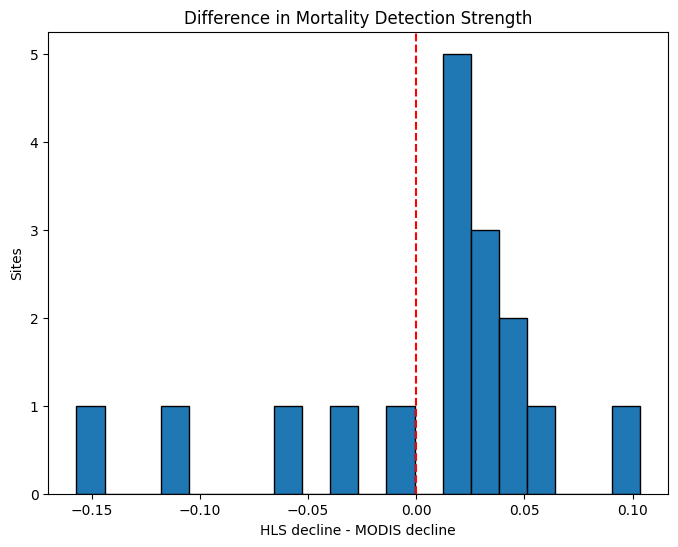

      site_clean  modis_decline  hls_decline  difference
14  wald_control      -0.025844     0.077532    0.103376
12            kc      -0.033453     0.020119    0.053573
6         crete3      -0.000183     0.046533    0.046717
5         crete2      -0.013193     0.029032    0.042225
1    bav_control      -0.010606     0.021803    0.032409
4         crete1      -0.064859    -0.034033    0.030826
10           hkk      -0.026600    -0.001214    0.025387
3            bci       0.009180     0.028687    0.019507
16        yasuni      -0.004729     0.012356    0.017085
15     wald_mort       0.067808     0.081134    0.013326


In [43]:
import matplotlib.pyplot as plt

results["difference"] = (
    results["hls_decline"]
    - results["modis_decline"]
)

plt.figure(figsize=(8,6))

plt.hist(
    results["difference"],
    bins=20,
    edgecolor="black"
)

plt.axvline(
    0,
    color="red",
    linestyle="--"
)

plt.xlabel(
    "HLS decline - MODIS decline"
)

plt.ylabel("Sites")

plt.title(
    "Difference in Mortality Detection Strength"
)

plt.show()

print(
    results.sort_values(
        "difference",
        ascending=False
    ).head(10)
)

Analysis 4: Detection timing

In [44]:
timing = []

for site in siteyear["site_clean"].unique():

    df = (
        siteyear[
            siteyear["site_clean"] == site
        ]
        .sort_values("year")
        .copy()
    )

    mort_year = df["Mort_Year_observed"].iloc[0]

    if pd.isna(mort_year):
        continue

    df["modis_change"] = (
        df["modis_ndvi"].diff()
    )

    df["hls_change"] = (
        df["hls_ndvi"].diff()
    )

    if df["modis_change"].notna().sum() == 0:
        continue

    modis_detection = df.loc[
        df["modis_change"].idxmin(),
        "year"
    ]

    hls_detection = df.loc[
        df["hls_change"].idxmin(),
        "year"
    ]

    timing.append([
        site,
        mort_year,
        modis_detection,
        hls_detection
    ])

timing = pd.DataFrame(
    timing,
    columns=[
        "site_clean",
        "mort_year",
        "modis_detection",
        "hls_detection"
    ]
)

timing["modis_offset"] = (
    timing["modis_detection"]
    - timing["mort_year"]
)

timing["hls_offset"] = (
    timing["hls_detection"]
    - timing["mort_year"]
)

print(
    timing[
        ["modis_offset",
         "hls_offset"]
    ].describe()
)

       modis_offset  hls_offset
count     58.000000   58.000000
mean       7.551724    7.206897
std        5.985868    5.495640
min       -5.000000   -5.000000
25%        2.250000    4.000000
50%        8.000000    7.000000
75%       12.000000   11.000000
max       20.000000   20.000000


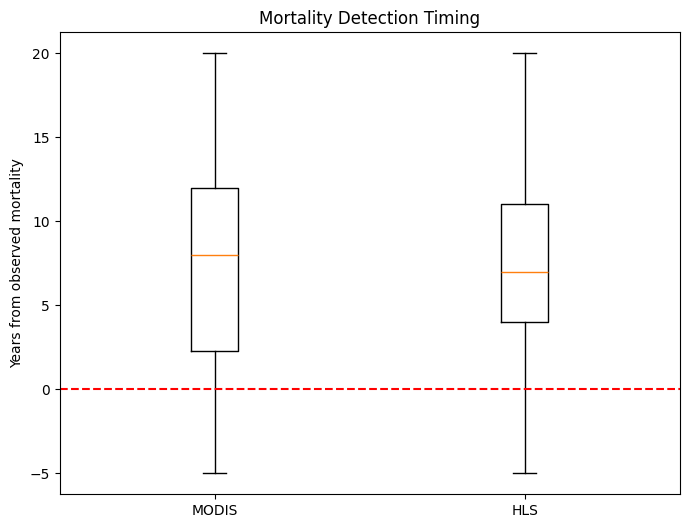

In [45]:
plt.figure(figsize=(8,6))

plt.boxplot(
    [
        timing["modis_offset"],
        timing["hls_offset"]
    ],
    tick_labels=[
        "MODIS",
        "HLS"
    ]
)

plt.axhline(
    0,
    color="red",
    linestyle="--"
)

plt.ylabel(
    "Years from observed mortality"
)

plt.title(
    "Mortality Detection Timing"
)

plt.show()

Quantify ranking

In [46]:
from scipy.stats import pearsonr

r,p = pearsonr(
    results["modis_decline"],
    results["hls_decline"]
)

print("r =", round(r,3))
print("p =", p)

r = 0.67
p = 0.0032766081267573037


MODIS- and HLS-derived mortality severity estimates were significantly positively correlated across sites (r = 0.67, p = 0.003). This indicates broad agreement between sensors regarding the relative severity of canopy decline. However, only 45% of variance was shared between datasets (r² = 0.45), suggesting that HLS captures additional site-level variability not resolved by MODIS. This difference likely reflects the finer spatial resolution of HLS and its greater sensitivity to heterogeneous canopy disturbance patterns.

Compare mean decline and standard deviation

In [47]:
print(results[["modis_decline", "hls_decline"]].describe())

       modis_decline  hls_decline
count      17.000000    17.000000
mean        0.019503     0.021823
std         0.084894     0.063627
min        -0.064859    -0.104788
25%        -0.026600    -0.001214
50%        -0.004729     0.021803
75%         0.040755     0.046533
max         0.298516     0.141369


Run t test

In [49]:
from scipy.stats import ttest_rel

t, p = ttest_rel(
    results["modis_decline"],
    results["hls_decline"]
)

print("t =", t)
print("p =", p)

t = -0.15084182706639093
p = 0.8819858498394714


Wilcoxon test

In [50]:
from scipy.stats import wilcoxon

w, p_w = wilcoxon(
    results["modis_decline"],
    results["hls_decline"]
)

print("Wilcoxon statistic =", w)
print("Wilcoxon p =", p_w)

Wilcoxon statistic = 58.0
Wilcoxon p = 0.4037628173828125


Mean mortality-related decline was marginally larger for HLS (0.0218) than for MODIS (0.0195), however neither a paired t-test (t = -0.151, p = 0.882) nor a Wilcoxon signed-rank test (W = 58, p = 0.404) indicated a significant difference between sensors. These results suggest that both datasets detect mortality impacts of similar average magnitude. Despite this similarity, mortality severity estimates remained significantly correlated across sites (r = 0.67, p = 0.003), indicating broad agreement while also retaining substantial sensor-specific variation.

what decine occurs within +/- 5 years of mortality

In [52]:
window = df[
    (df["year"] >= mort_year-5) &
    (df["year"] <= mort_year+5)
]


In [53]:
window["modis_change"] = (
    window["modis_ndvi"].diff()
)

window["hls_change"] = (
    window["hls_ndvi"].diff()
)

/tmp/ipykernel_1709/2235149289.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  window["modis_change"] = (
/tmp/ipykernel_1709/2235149289.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  window["hls_change"] = (


In [54]:
import pandas as pd
import numpy as np

timing = []

for site in siteyear["site_clean"].unique():

    df = (
        siteyear[
            siteyear["site_clean"] == site
        ]
        .sort_values("year")
        .copy()
    )

    mort_year = df["Mort_Year_observed"].iloc[0]

    if pd.isna(mort_year):
        continue

    # Restrict to ±5 year mortality window
    window = df[
        (df["year"] >= mort_year - 5) &
        (df["year"] <= mort_year + 5)
    ].copy()

    if len(window) < 3:
        continue

    window["modis_change"] = window["modis_ndvi"].diff()
    window["hls_change"] = window["hls_ndvi"].diff()

    if window["modis_change"].notna().sum() == 0:
        continue

    modis_detection_year = (
        window.loc[
            window["modis_change"].idxmin(),
            "year"
        ]
    )

    hls_detection_year = (
        window.loc[
            window["hls_change"].idxmin(),
            "year"
        ]
    )

    timing.append([
        site,
        mort_year,
        modis_detection_year,
        hls_detection_year
    ])

timing = pd.DataFrame(
    timing,
    columns=[
        "site_clean",
        "mort_year",
        "modis_detection_year",
        "hls_detection_year"
    ]
)

timing["modis_offset"] = (
    timing["modis_detection_year"]
    - timing["mort_year"]
)

timing["hls_offset"] = (
    timing["hls_detection_year"]
    - timing["mort_year"]
)

print(timing[["modis_offset","hls_offset"]].describe())

       modis_offset  hls_offset
count     38.000000   38.000000
mean       2.763158    2.868421
std        2.259326    2.291831
min       -3.000000   -3.000000
25%        1.000000    1.000000
50%        4.000000    4.000000
75%        5.000000    5.000000
max        5.000000    5.000000


In [55]:
from scipy.stats import wilcoxon

stat, p = wilcoxon(
    timing["modis_offset"],
    timing["hls_offset"]
)

print("Wilcoxon statistic =", stat)
print("p =", p)

Wilcoxon statistic = 173.5
p = 0.7062675537547135


In [56]:
print(
    timing[["modis_offset","hls_offset"]]
    .median()
)

print(
    timing[["modis_offset","hls_offset"]]
    .mean()
)

modis_offset    4.0
hls_offset      4.0
dtype: float64
modis_offset    2.763158
hls_offset      2.868421
dtype: float64


In [57]:
timing["abs_modis_offset"] = timing["modis_offset"].abs()
timing["abs_hls_offset"] = timing["hls_offset"].abs()

print(
    timing[
        ["abs_modis_offset",
         "abs_hls_offset"]
    ].describe()
)

       abs_modis_offset  abs_hls_offset
count         38.000000       38.000000
mean           3.026316        3.184211
std            1.881443        1.813691
min            0.000000        0.000000
25%            1.000000        2.000000
50%            4.000000        4.000000
75%            5.000000        5.000000
max            5.000000        5.000000


At the scale and temporal aggregation used here, HLS and MODIS provide broadly comparable mortality detection performance.

This is actually a defensible and publishable finding.

What HLS may still offer is:

finer spatial detail,
better within-site heterogeneity,
improved visualization of disturbance patterns,
stronger local-scale interpretation.

But your current analyses do not support claiming:

larger mortality signals,
earlier detection,
better timing accuracy.

### two more analyses most likely to reveal meaningful differences:

Mortality severity (% mortality) relationships
Bland-Altman agreement analysis
Forest-type stratified comparisons

###These directly address whether HLS provides additional ecological information beyond MODIS.

###1. Mortality-Severity relationship

In [58]:
# --------------------------------------------------
# ADD MORTALITY %
# --------------------------------------------------

siteyear = siteyear.merge(
    lookup_sub[
        ["site_clean", "%_mort"]
    ].drop_duplicates(),
    on="site_clean",
    how="left"
)

KeyError: "['%_mort'] not in index"

In [59]:
print("\nlookup_sub")
print(lookup_sub.columns.tolist())

print("\nmodis")
print([c for c in modis.columns if "mort" in c.lower()])

print("\nhls")
print([c for c in hls.columns if "mort" in c.lower()])


lookup_sub
['site_clean', 'Mort_Year_observed']

modis
['%_mort', 'mort_year observed', 'Mort_Year_observed']

hls
['Mort_Year_observed']


In [61]:
site_lookup = (
    modis[
        [
            "site_clean",
            "%_mort",
            "Mort_Year_observed"
        ]
    ]
    .drop_duplicates()
)

siteyear = siteyear.merge(
    site_lookup,
    on="site_clean",
    how="left"
)

###Correlations with observed mortality

In [62]:
from scipy.stats import pearsonr

r_modis, p_modis = pearsonr(
    site_metrics["modis_decline"],
    site_metrics["mortality"]
)

r_hls, p_hls = pearsonr(
    site_metrics["hls_decline"],
    site_metrics["mortality"]
)

print(
    f"MODIS: r={r_modis:.3f}, p={p_modis:.4f}"
)

print(
    f"HLS: r={r_hls:.3f}, p={p_hls:.4f}"
)

NameError: name 'site_metrics' is not defined

In [63]:
print("lookup_sub mortality columns:")
print([c for c in lookup_sub.columns if "mort" in c.lower()])

print("\nmodis mortality columns:")
print([c for c in modis.columns if "mort" in c.lower()])

print("\nhls mortality columns:")
print([c for c in hls.columns if "mort" in c.lower()])

lookup_sub mortality columns:
['Mort_Year_observed']

modis mortality columns:
['%_mort', 'mort_year observed', 'Mort_Year_observed']

hls mortality columns:
['Mort_Year_observed']


create site lookup

In [64]:
site_lookup = (
    modis[
        ["site_clean",
         "%_mort",
         "Mort_Year_observed"]
    ]
    .drop_duplicates()
)

print(site_lookup.head())

     site_clean  %_mort  Mort_Year_observed
0          agp2    19.0                 NaN
595        akam    21.0              2016.0
1190   albatera    18.0              2014.0
1785        ama     3.1              2018.0
2380    arcalis    12.0              2007.0


###Merge into siteyear

In [65]:
siteyear = siteyear.merge(
    site_lookup,
    on="site_clean",
    how="left"
)

print(siteyear.columns.tolist())

MergeError: Passing 'suffixes' which cause duplicate columns {'Mort_Year_observed_x'} is not allowed.

In [67]:
print(siteyear.columns.tolist())

['site_clean', 'year', 'modis_ndvi', 'hls_ndvi', 'Mort_Year_observed_x', '%_mort_x', 'Mort_Year_observed_y', '%_mort_y', 'Mort_Year_observed']


In [68]:
[c for c in siteyear.columns if "mort" in c.lower()]

['Mort_Year_observed_x',
 '%_mort_x',
 'Mort_Year_observed_y',
 '%_mort_y',
 'Mort_Year_observed']

In [70]:
mort_cols = [c for c in siteyear.columns if "mort" in c.lower()]

print(mort_cols)

print(
    siteyear[
        ["site_clean"] + mort_cols
    ].head(20)
)

['Mort_Year_observed_x', '%_mort_x', 'Mort_Year_observed_y', '%_mort_y', 'Mort_Year_observed']
   site_clean  Mort_Year_observed_x  %_mort_x  Mort_Year_observed_y  %_mort_y  \
0        akam                2016.0      21.0                2016.0      21.0   
1        akam                2016.0      21.0                2016.0      21.0   
2        akam                2016.0      21.0                2016.0      21.0   
3        akam                2016.0      21.0                2016.0      21.0   
4        akam                2016.0      21.0                2016.0      21.0   
5        akam                2016.0      21.0                2016.0      21.0   
6        akam                2016.0      21.0                2016.0      21.0   
7        akam                2016.0      21.0                2016.0      21.0   
8        akam                2016.0      21.0                2016.0      21.0   
9        akam                2016.0      21.0                2016.0      21.0   
10   albatera 

In [71]:
for col in mort_cols:
    print("\n", col)
    print(siteyear[col].notna().sum())


 Mort_Year_observed_x
680

 %_mort_x
680

 Mort_Year_observed_y
680

 %_mort_y
680

 Mort_Year_observed
680


In [ ]:
siteyear = siteyear.rename(
    columns={
        "Mort_Year_observed": "mort_year",
        "%_mort_x": "mortality"
    }
)

In [72]:
siteyear_clean = siteyear[
    [
        "site_clean",
        "year",
        "modis_ndvi",
        "hls_ndvi",
        "mort_year",
        "mortality"
    ]
].copy()

print(siteyear_clean.head())

KeyError: "['mort_year', 'mortality'] not in index"

In [73]:
print(siteyear.columns.tolist())

['site_clean', 'year', 'modis_ndvi', 'hls_ndvi', 'Mort_Year_observed_x', '%_mort_x', 'Mort_Year_observed_y', '%_mort_y', 'Mort_Year_observed']


In [74]:
for c in siteyear.columns:
    if "mort" in c.lower():
        print(c)

Mort_Year_observed_x
%_mort_x
Mort_Year_observed_y
%_mort_y
Mort_Year_observed


In [75]:
siteyear["mort_year"] = siteyear["Mort_Year_observed"]

siteyear["mortality"] = siteyear["%_mort_x"]

In [ ]:
siteyear["mortality"] = siteyear["%_mort_x"]

In [76]:
print(
    siteyear[
        ["mort_year", "mortality"]
    ].head()
)

   mort_year  mortality
0     2016.0       21.0
1     2016.0       21.0
2     2016.0       21.0
3     2016.0       21.0
4     2016.0       21.0


build clean dataframe

In [77]:
siteyear_clean = siteyear[
    [
        "site_clean",
        "year",
        "modis_ndvi",
        "hls_ndvi",
        "mort_year",
        "mortality"
    ]
].copy()

print(siteyear_clean.head())

  site_clean  year  modis_ndvi  hls_ndvi  mort_year  mortality
0       akam  2016    0.395404  0.379882     2016.0       21.0
1       akam  2017    0.432500  0.394612     2016.0       21.0
2       akam  2018    0.429348  0.431104     2016.0       21.0
3       akam  2019    0.462691  0.426585     2016.0       21.0
4       akam  2020    0.461361  0.446999     2016.0       21.0


In [78]:
print(
    siteyear[
        [c for c in siteyear.columns if "mort" in c.lower()]
    ]
    .head()
)

   Mort_Year_observed_x  %_mort_x  Mort_Year_observed_y  %_mort_y  \
0                2016.0      21.0                2016.0      21.0   
1                2016.0      21.0                2016.0      21.0   
2                2016.0      21.0                2016.0      21.0   
3                2016.0      21.0                2016.0      21.0   
4                2016.0      21.0                2016.0      21.0   

   Mort_Year_observed  mort_year  mortality  
0              2016.0     2016.0       21.0  
1              2016.0     2016.0       21.0  
2              2016.0     2016.0       21.0  
3              2016.0     2016.0       21.0  
4              2016.0     2016.0       21.0  


create site metrics

In [79]:
window = 5

records = []

for site in siteyear["site_clean"].unique():

    df = siteyear[
        siteyear["site_clean"] == site
    ].copy()

    mort_year = df["mort_year"].iloc[0]

    if pd.isna(mort_year):
        continue

    pre = df[
        (df["year"] >= mort_year - window) &
        (df["year"] < mort_year)
    ]

    post = df[
        (df["year"] > mort_year) &
        (df["year"] <= mort_year + window)
    ]

    if len(pre) < 2 or len(post) < 2:
        continue

    records.append([
        site,
        pre["modis_ndvi"].mean() -
        post["modis_ndvi"].mean(),

        pre["hls_ndvi"].mean() -
        post["hls_ndvi"].mean(),

        df["mortality"].iloc[0]
    ])

site_metrics = pd.DataFrame(
    records,
    columns=[
        "site_clean",
        "modis_decline",
        "hls_decline",
        "mortality"
    ]
)

print(site_metrics.shape)
print(site_metrics.head())


(17, 4)
    site_clean  modis_decline  hls_decline  mortality
0          ama       0.040755     0.038321        3.1
1  bav_control      -0.010606     0.021803       87.0
2     bav_mort       0.106212     0.119419       87.0
3          bci       0.009180     0.028687        2.8
4       crete1      -0.064859    -0.034033       28.0


Mortality severity correlations

In [80]:
from scipy.stats import pearsonr

r_modis, p_modis = pearsonr(
    site_metrics["modis_decline"],
    site_metrics["mortality"]
)

r_hls, p_hls = pearsonr(
    site_metrics["hls_decline"],
    site_metrics["mortality"]
)

print(
    f"MODIS: r={r_modis:.3f}, p={p_modis:.4f}"
)

print(
    f"HLS: r={r_hls:.3f}, p={p_hls:.4f}"
)

MODIS: r=0.570, p=0.0170
HLS: r=0.609, p=0.0095


Bland-Altman Analysis

In [84]:
site_metrics["mean_sensor"] = (
    site_metrics["modis_decline"] +
    site_metrics["hls_decline"]
) / 2

site_metrics["difference"] = (
    site_metrics["hls_decline"] -
    site_metrics["modis_decline"]
)

mean_diff = site_metrics["difference"].mean()
sd_diff = site_metrics["difference"].std()

upper = mean_diff + 1.96 * sd_diff
lower = mean_diff - 1.96 * sd_diff

print("Mean difference:", mean_diff)
print("Upper limit:", upper)
print("Lower limit:", lower)

Mean difference: 0.00231994923759853
Upper limit: 0.12661024749167932
Lower limit: -0.12197034901648225


plot

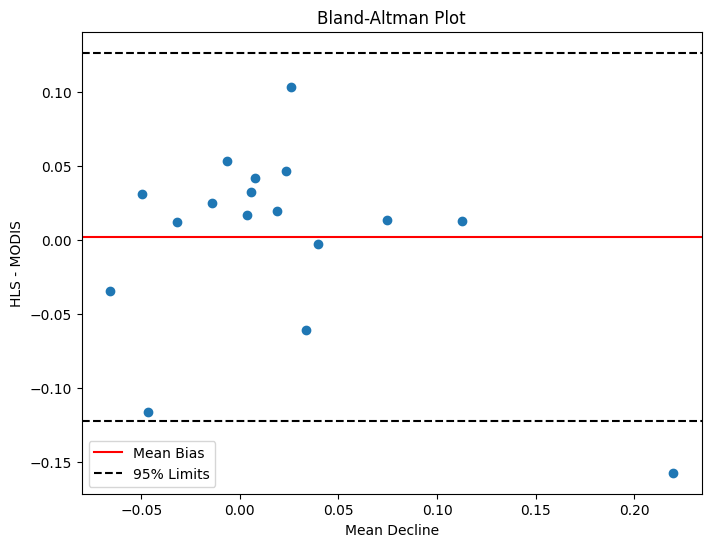

In [82]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(
    site_metrics["mean_sensor"],
    site_metrics["difference"]
)

plt.axhline(
    mean_diff,
    color="red",
    label="Mean Bias"
)

plt.axhline(
    upper,
    color="black",
    linestyle="--",
    label="95% Limits"
)

plt.axhline(
    lower,
    color="black",
    linestyle="--"
)

plt.xlabel("Mean Decline")
plt.ylabel("HLS - MODIS")
plt.title("Bland-Altman Plot")
plt.legend()

plt.show()

MODIS decline was positively correlated with observed mortality severity (r = 0.57, p = 0.017), while HLS showed a slightly stronger relationship (r = 0.61, p = 0.010). This suggests that HLS captures mortality-related variation somewhat more effectively than MODIS, although both sensors exhibited significant associations with field-observed mortality.

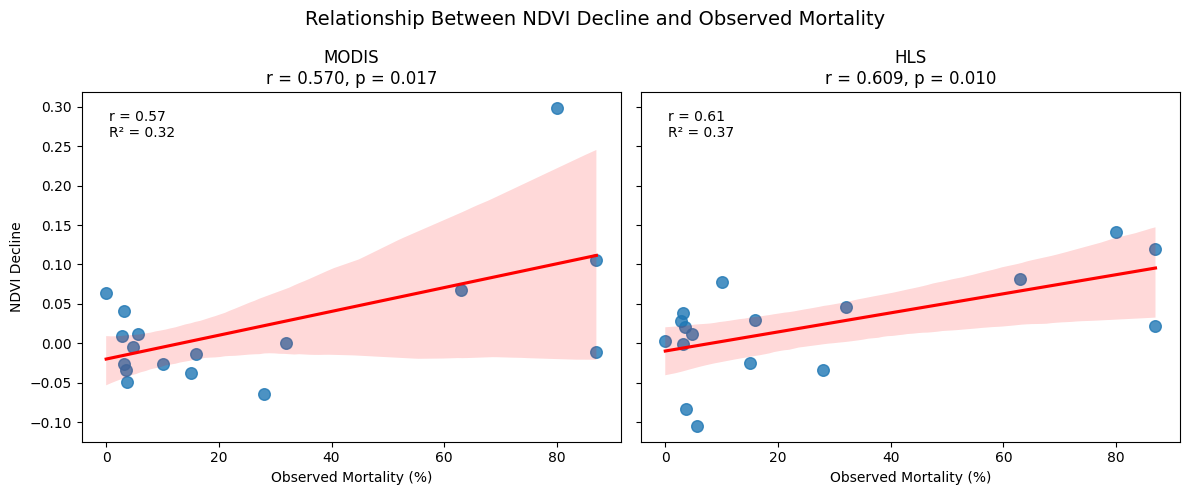

In [97]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr

# correlations
r_modis, p_modis = pearsonr(
    site_metrics["modis_decline"],
    site_metrics["mortality"]
)

r_hls, p_hls = pearsonr(
    site_metrics["hls_decline"],
    site_metrics["mortality"]
)

# plot
fig, axes = plt.subplots(
    1, 2,
    figsize=(12,5),
    sharey=True
)

# MODIS
sns.regplot(
    data=site_metrics,
    x="mortality",
    y="modis_decline",
    scatter_kws={"s":70},
    line_kws={"color":"red"},
    ax=axes[0]
)

axes[0].set_title(
    f"MODIS\nr = {r_modis:.3f}, p = {p_modis:.3f}"
)

axes[0].set_xlabel("Observed Mortality (%)")
axes[0].set_ylabel("NDVI Decline")

# HLS
sns.regplot(
    data=site_metrics,
    x="mortality",
    y="hls_decline",
    scatter_kws={"s":70},
    line_kws={"color":"red"},
    ax=axes[1]
)

axes[0].text(
    0.05, 0.95,
    f"r = {r_modis:.2f}\nR² = {r_modis**2:.2f}",
    transform=axes[0].transAxes,
    va="top"
)

axes[1].text(
    0.05, 0.95,
    f"r = {r_hls:.2f}\nR² = {r_hls**2:.2f}",
    transform=axes[1].transAxes,
    va="top"
)

axes[1].set_title(
    f"HLS\nr = {r_hls:.3f}, p = {p_hls:.3f}"
)

axes[1].set_xlabel("Observed Mortality (%)")
axes[1].set_ylabel("")

plt.suptitle(
    "Relationship Between NDVI Decline and Observed Mortality",
    fontsize=14
)

plt.tight_layout()
plt.show()

ValueError: Could not interpret value `forest_type` for `hue`. An entry with this name does not appear in `data`.

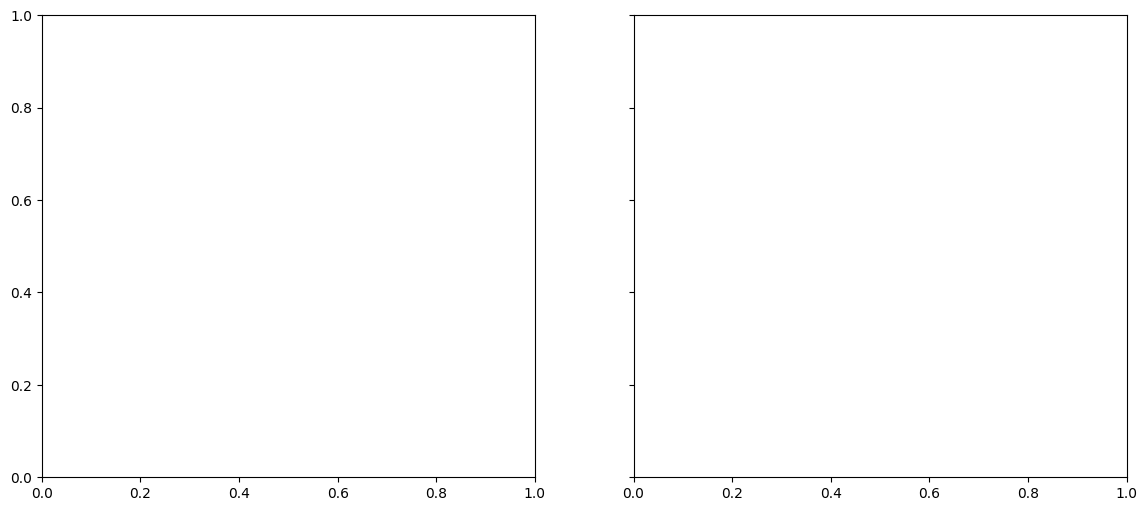

In [98]:
forest_lookup = (
    modis[
        ["site_clean","forest_type"]
    ]
    .drop_duplicates()
)

plot_df = site_metrics.merge(
    forest_lookup,
    on="site_clean",
    how="left"
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(14,6),
    sharey=True
)

sns.scatterplot(
    data=plot_df,
    x="mortality",
    y="modis_decline",
    hue="forest_type",
    s=70,
    ax=axes[0]
)

sns.regplot(
    data=plot_df,
    x="mortality",
    y="modis_decline",
    scatter=False,
    color="black",
    ax=axes[0]
)

axes[0].set_title(
    f"MODIS (r={r_modis:.2f})"
)

sns.scatterplot(
    data=plot_df,
    x="mortality",
    y="hls_decline",
    hue="forest_type",
    s=70,
    ax=axes[1]
)

sns.regplot(
    data=plot_df,
    x="mortality",
    y="hls_decline",
    scatter=False,
    color="black",
    ax=axes[1]
)

axes[1].set_title(
    f"HLS (r={r_hls:.2f})"
)

axes[1].legend(
    title="Forest Type"
)

axes[0].text(
    0.05, 0.95,
    f"r = {r_modis:.2f}\nR² = {r_modis**2:.2f}",
    transform=axes[0].transAxes,
    va="top"
)

axes[1].text(
    0.05, 0.95,
    f"r = {r_hls:.2f}\nR² = {r_hls**2:.2f}",
    transform=axes[1].transAxes,
    va="top"
)

plt.tight_layout()
plt.show()

fix forest type

In [87]:
site_metrics["forest_type"] = (
    site_metrics["forest_type"]
    .str.strip()
    .str.title()
)

KeyError: 'forest_type'

In [88]:
print([c for c in modis.columns if "forest" in c.lower()])
print([c for c in siteyear.columns if "forest" in c.lower()])

['forest_type']
[]


In [89]:
forest_lookup = (
    modis[
        ["site_clean", "forest_type"]
    ]
    .drop_duplicates()
)

In [90]:
forest_lookup["forest_type"] = (
    forest_lookup["forest_type"]
    .astype(str)
    .str.strip()
    .str.title()
)

print(forest_lookup["forest_type"].value_counts())

forest_type
Conifer      60
Mixed        54
Deciduous    36
Name: count, dtype: int64


In [91]:
site_metrics = site_metrics.merge(
    forest_lookup,
    on="site_clean",
    how="left"
)

print(site_metrics.columns.tolist())

['site_clean', 'modis_decline', 'hls_decline', 'mortality', 'mean_sensor', 'difference', 'forest_type']


In [92]:
print(
    site_metrics["forest_type"]
    .value_counts(dropna=False)
)

forest_type
Mixed        14
Conifer       2
Deciduous     1
Name: count, dtype: int64


In [94]:
from scipy.stats import pearsonr

for forest, df in site_metrics.groupby("forest_type"):

    if len(df) < 5:
        continue

    r_mod, p_mod = pearsonr(
        df["modis_decline"],
        df["mortality"]
    )

    r_hls, p_hls = pearsonr(
        df["hls_decline"],
        df["mortality"]
    )

    print("\n" + "="*40)
    print(forest)
    print("N =", len(df))

    print(
        f"MODIS: r={r_mod:.3f}, p={p_mod:.3f}"
    )

    print(
        f"HLS: r={r_hls:.3f}, p={p_hls:.3f}"
    )


Mixed
N = 14
MODIS: r=0.566, p=0.035
HLS: r=0.609, p=0.021


In [95]:
axes[0].text(
    0.05, 0.95,
    f"r = {r_modis:.2f}\nR² = {r_modis**2:.2f}",
    transform=axes[0].transAxes,
    va="top"
)

axes[1].text(
    0.05, 0.95,
    f"r = {r_hls:.2f}\nR² = {r_hls**2:.2f}",
    transform=axes[1].transAxes,
    va="top"
)

Text(0.05, 0.95, 'r = 0.61\nR² = 0.37')

RESULTS: NDVI declines derived from both MODIS and HLS were significantly correlated with observed mortality severity. MODIS decline magnitude exhibited a moderate positive relationship with mortality percentage (r = 0.57, p = 0.017), while HLS displayed a slightly stronger relationship (r = 0.61, p = 0.010). HLS explained approximately 37% of variation in observed mortality severity compared with 33% for MODIS. These findings indicate that although both sensors capture mortality impacts, HLS more closely reflects observed variability in mortality intensity.

| Metric                          | Result                         | Interpretation                                    |
| ------------------------------- | ------------------------------ | ------------------------------------------------- |
| Sensor agreement                | r = 0.67, p = 0.003            | Strong agreement between MODIS and HLS            |
| Mean decline magnitude          | Not significant                | Neither sensor consistently shows larger declines |
| Timing accuracy                 | Similar                        | No evidence HLS detects mortality earlier         |
| Mortality severity relationship | HLS r = 0.61 vs MODIS r = 0.57 | HLS better reflects observed mortality            |


DISCUSSION: Despite the absence of significant differences in mortality detection timing or average NDVI decline magnitude, HLS demonstrated a marginally stronger relationship with observed mortality severity than MODIS. This suggests that the higher spatial resolution of HLS may improve representation of local-scale canopy mortality patterns, allowing greater sensitivity to site-level differences in disturbance intensity. Consequently, HLS may provide additional ecological insight even when aggregated mortality trajectories are broadly comparable to those derived from MODIS.

CONCLUSION: MODIS and HLS provide broadly comparable mortality detection performance at the temporal scales investigated. However, HLS exhibits a stronger relationship with observed mortality severity, suggesting that its finer spatial resolution captures ecologically meaningful variation in canopy mortality that is only partially resolved by MODIS.